# Introduction

### Coffee Shop Order Cohort Analysis

This analysis explores customer behavior, order preferences, and revenue growth using different time-based cohort approaches. By calculating retention rates for customers and products, their engagement with the business can be observed across different units of time, providing a basis for strategic and operational decisions. Revenue growth is also analyzed by calculating the cumulative increase in revenue over time.

The dataset used in this analysis is synthetically generated to mimic an existing coffee shop in Tarlac City, Philippines. Although the data is simulated, the distributions of customers, orders, prices, and purchase times are designed to realistically represent the patterns of an actual coffee shop.

The main goals of this Analysis is to:
1. Understand Business Behavior and Retention.
2. Provide An Overview On Revenue Growth.
3. Explore Different Time-Based Cohorts.
4. Perform An Exploratory Analysis To Understand The Business.
5. Answer Business Questions Related To Customer Engagement.
6. Provide Insights.

In [1]:
# import libraries
import numpy as np
import pandas as pd
import datetime as dt
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# The Dataset

In [2]:
# reading in csv
csv_link = 'https://raw.githubusercontent.com/kierzarate10/Synthetic-Coffee-'\
'Shop-Customer-and-Transaction-Generator/refs/heads/main/orders.csv'
orders = pd.read_csv(csv_link)
orders = orders.sort_values('order_date')
orders



,order_id,order_date,customer_id,age,gender,income,payment_method,part_of_day,age_group,order,Price,order_category,time
99213,ORD-67560,2022-01-02,b95e44e3,51,Female,29100.0,Cash,evening,older,Americano,100,Drinks,18:02:08
137933,ORD-939323,2022-01-02,b95e44e3,51,Female,29100.0,Cash,afternoon,older,Caldereta,345,Meal,17:05:29
137932,ORD-939323,2022-01-02,b95e44e3,51,Female,29100.0,Cash,afternoon,older,Burger Steak,320,Meal,17:05:29
3798,ORD-025992,2022-01-02,b95e44e3,51,Female,29100.0,Card,afternoon,older,Kare-Kare,375,Meal,17:03:47
99214,ORD-67560,2022-01-02,b95e44e3,51,Female,29100.0,Cash,evening,older,Caldereta,345,Meal,18:02:08
...,...,...,...,...,...,...,...,...,...,...,...,...,...
71841,ORD-489327,2026-01-01,1ccc33c1,58,Female,20800.0,Cash,evening,older,Carbonara,280,Meal,19:36:37
109466,ORD-74579,2026-01-01,d00dcc4f,45,Female,41700.0,Cash,evening,middle,Barista's Drink,155,Drinks,18:24:25
63378,ORD-430839,2026-01-01,7f53d344,44,Female,40600.0,Cash,evening,middle,Spaghetti Bolognese,215,Meal,20:48:13
137072,ORD-933678,2026-01-01,02b3c948,37,Female,24200.0,Cash,evening,middle,Carbonara,280,Meal,19:19:49


* Coffee shop orders dataset has 147,062 rows and 13 columns.
* The dataset has 4 years of data from January 2022 to January 2026.
* Each row represents a unique order.
* order_id that is repeated are multiple orders in a single time.

In [3]:
# dataset info
orders.info()

<class 'pandas.core.frame.DataFrame'>
Index: 147062 entries, 99213 to 63377
Data columns (total 13 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   order_id        147062 non-null  object 
 1   order_date      147062 non-null  object 
 2   customer_id     147062 non-null  object 
 3   age             147062 non-null  int64  
 4   gender          147062 non-null  object 
 5   income          147062 non-null  float64
 6   payment_method  147062 non-null  object 
 7   part_of_day     147062 non-null  object 
 8   age_group       147062 non-null  object 
 9   order           147062 non-null  object 
 10  Price           147062 non-null  int64  
 11  order_category  147062 non-null  object 
 12  time            147062 non-null  object 
dtypes: float64(1), int64(2), object(10)
memory usage: 15.7+ MB


In [4]:
# basic stats
orders.describe()

,age,income,Price
count,147062.000000,147062.000000,147062.000000
mean,41.780317,28668.949151,244.623411
std,13.846290,12598.754583,97.334345
min,18.000000,5400.000000,95.000000
25%,31.000000,19800.000000,155.000000
50%,39.000000,26200.000000,260.000000
75%,49.000000,34600.000000,325.000000
max,90.000000,121600.000000,420.000000


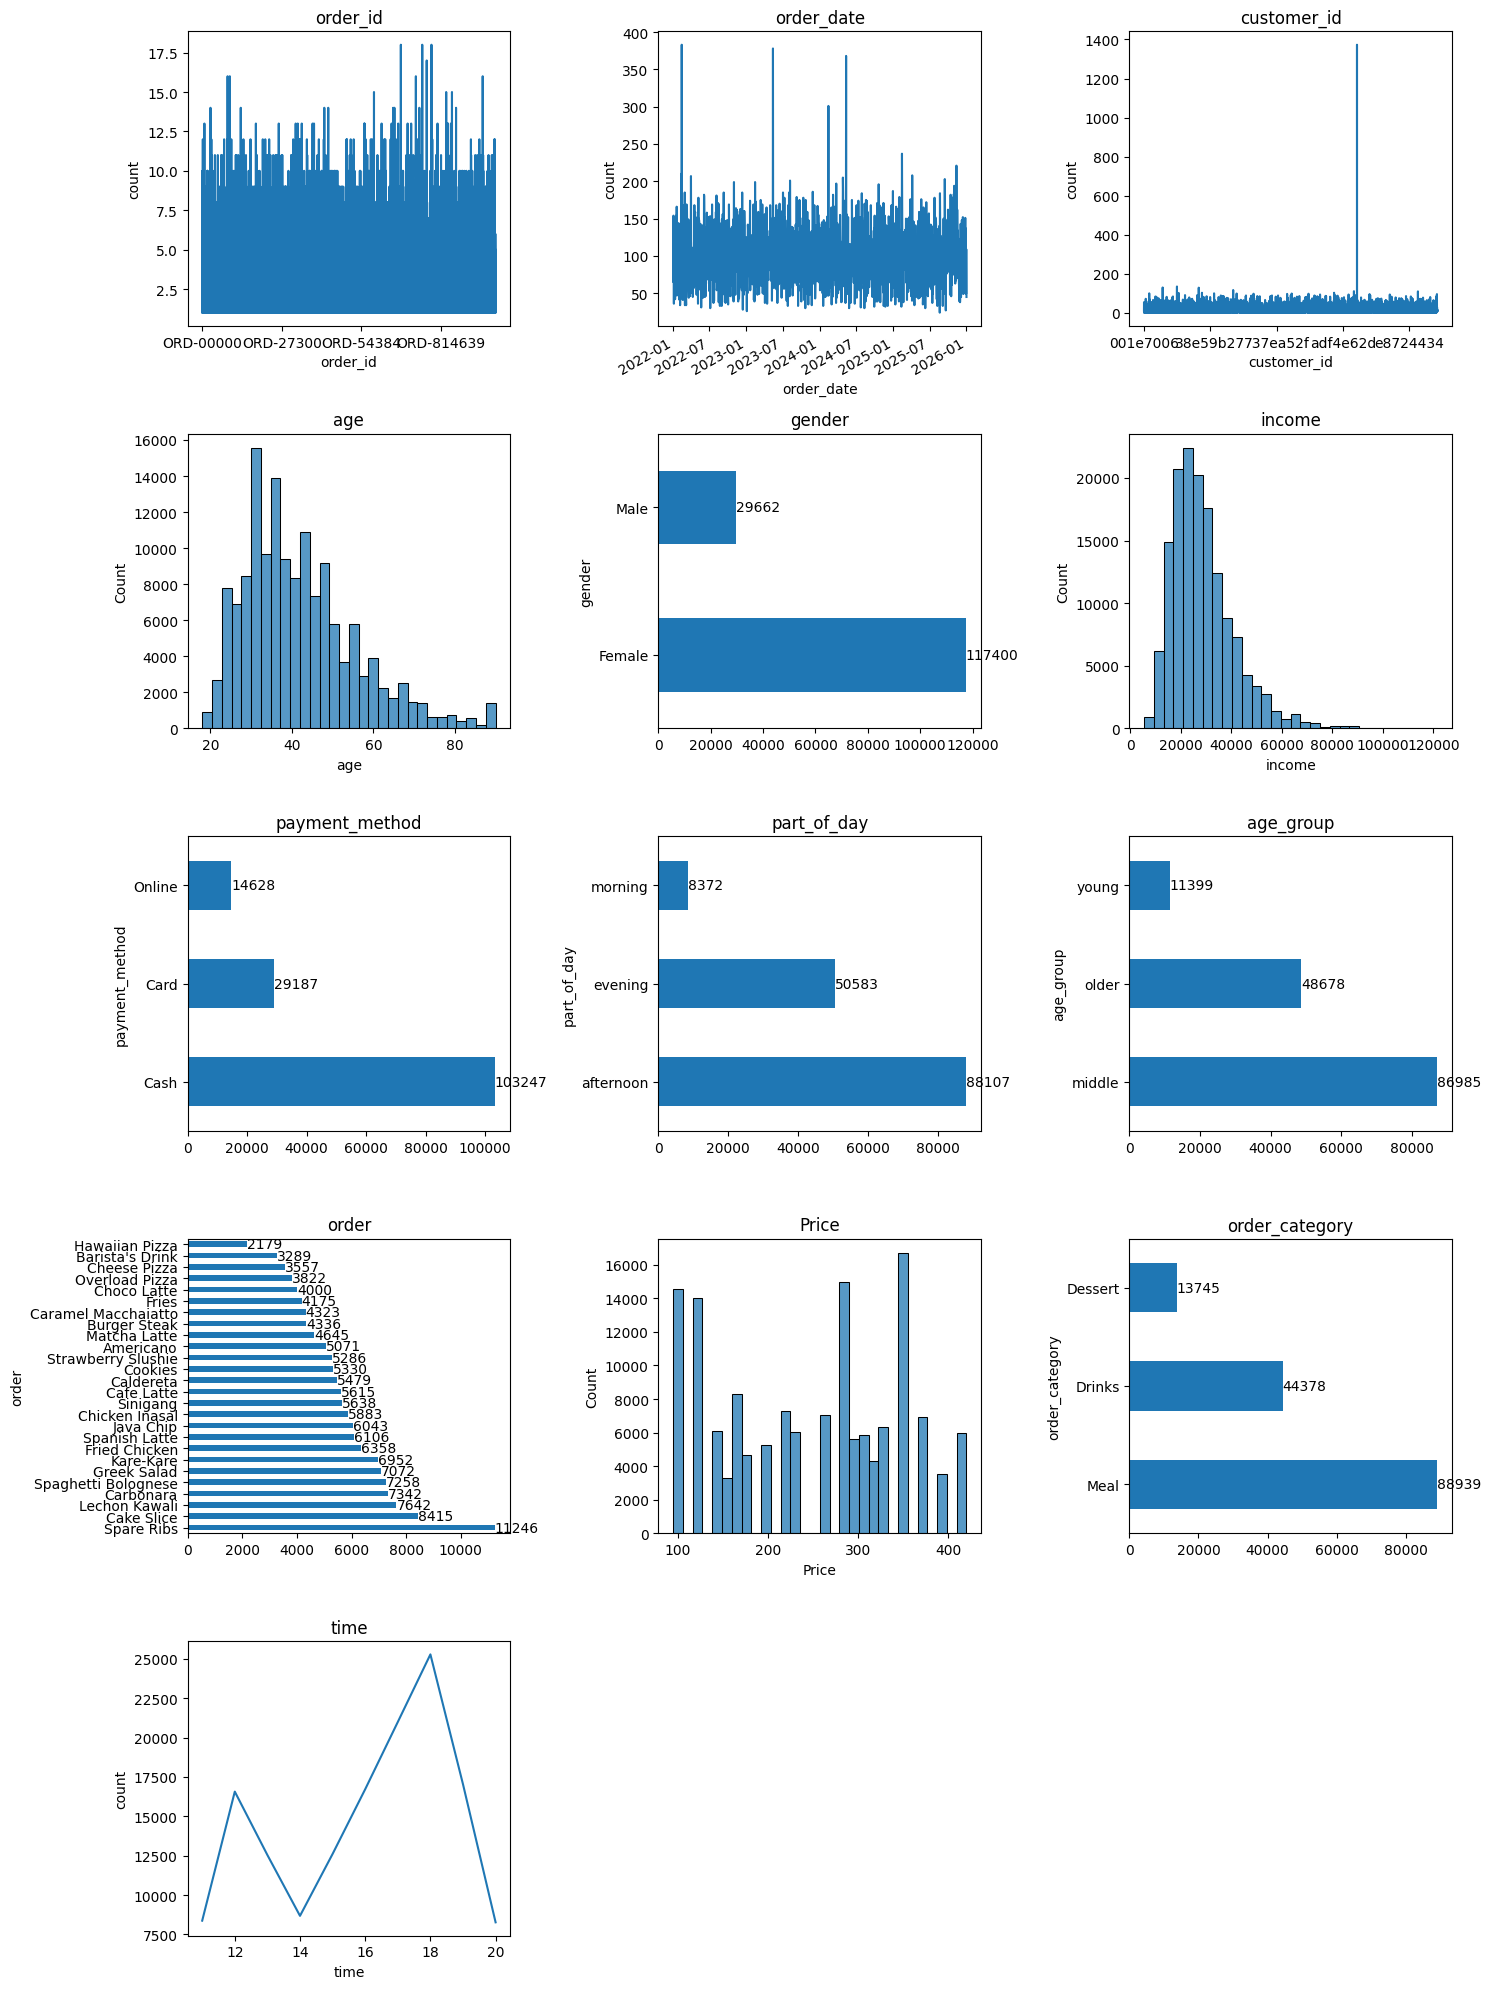

In [5]:
# distribution of each column

# create subplots
fig, axs = plt.subplots(nrows=5, ncols=3, figsize=(15,20))

# flatten axes for easier reference
ax = axs.flatten()
cols = orders.columns

# display each column distribution
for i, col in enumerate(cols):
  if col in ['age', 'income', 'Price']:
    sns.histplot(data=orders, x=col, ax=ax[i], bins=30)
  elif col in ['order_id', 'customer_id']:
    orders.groupby(col).size().plot(ax=ax[i])
    ax[i].set_ylabel('count')
  elif col == 'order_date':
    (
        orders.groupby(pd.to_datetime(orders[col]))
      .size().plot(x_compat=True,ax=ax[i])
    )
    ax[i].set_ylabel('count')
  elif col == 'time':
    (
        orders.groupby(pd.to_datetime(orders[col]).dt.hour)
      .size().plot(x_compat=True, ax=ax[i])
    )
    ax[i].set_ylabel('count')
  else:
    orders[col].value_counts().plot(kind='barh', ax=ax[i])
    ax[i].bar_label(ax[i].containers[0])
  ax[i].set_title(col)


# delete the excess axes
fig.delaxes(ax[13])
fig.delaxes(ax[14])



# tight layout to avoid labels overlapping
plt.tight_layout()



1.    The order_id distribution is a unique identifier for an order; each unique order_id represents single or multiple orders. order_id shows a uniformed distribution with random fluctuations, each unique order_id ranges from 1 to 20 orders

2.    The order_date distribution also shows uniformed distribution with observed repeated fluctuations on certain dates, which tells that there are special dates with high order count.

3.    The customer_id distribution also shows uniformed distribution with observed random order count fluctuations, indicating random customer purchase frequency. Customers order count for 4 years ranges from 1 to 220 approximately. This shows variation towards customer purchasing frequency.

4.    The age distribution is positively skewed; ages 30 to 45 are where most of the values concentrate.

5.    The gender distribution shows a high concentration of female customers approximately 80%, while 20% for male, indicating female customers make up most of the orders in 4 years.

6.  The income distribution is positively skewed, concentrating around 20,000 to 40,000 pesos.

7.    The payment_method variable is divided into Cash (70%), Card (20%), and Online payment (10%). Each customer randomly pays using these 3 payment methods.

8.    The part_of_day variable categorizes orders according to the time of the day in which they occur.

        * Morning (11:00 - 11:59) - since morning is only one hour, it only takes 4% of all the orders in 4 years.
    
        * Afternoon (12:00 - 5:59) - afternoon makes the highest order count with 52% orders in 4 years.
    
        * Evening (6:00 - 9:00) - evening which is only 3 hours makes up 44% of all orders in 4 years. Overall, afternoon makes the highest sales in a day.

9. The age_group variable is divided into three groups:

    * Young are aged from 18 to 25 years old (9%)

    * Middle is aged from 26 to 45 years old (59%)

    * Older are aged from 46 to 90 years old (32%).
  
      The division of the age group is based on differences in common dietary patterns for specific age intervals. This   shows that adults (aged 26 and above) are the most common customers and the business's target market.

10. The order variable represents the individual menu items being purchased. Spare ribs makes the highest order count for 4 years and is the best selling in the business, while hawaiian pizza makes the lowest. Spanish latte is the best-selling drink, and Cake slice is the best-selling dessert in the business.

11. The Price distribtuion is the amount of money paid for each menu item; each bin is represented by a menu item. Menu items with prices from 280 pesos to 350 pesos and 100 to 120 pesos are the most popular

12. The order_category variable is the division of each menu item based on its food category.

    * Desserts make up 9% of the total orders, which makes the least popular order category in 4 years.

    * Drinks make up 30% of the total orders for 4 years.

    * Meals make up 61% of the total orders, which makes the most popular order category in 4 years.

13. The time variable represents the orders unit of time in hours, minute and second; the visualization displays the distribution by hour of the day. 12:00 to 18:00 is the most popular time and makes the most of the orders in 4 years, this says that 12:00 to 18:00 is the time when most customers arrive and order. Lunch time (12) is at peak, and dinner time (6) is at peak, corresponding to lunch and dinner periods.



# Cohort Analysis

In [6]:
# convert order_date into a pandas datetime data type for easier reference.
orders['order_date'] = pd.to_datetime(orders['order_date'], format='%Y-%m-%d')

orders.info()

<class 'pandas.core.frame.DataFrame'>
Index: 147062 entries, 99213 to 63377
Data columns (total 13 columns):
 #   Column          Non-Null Count   Dtype         
---  ------          --------------   -----         
 0   order_id        147062 non-null  object        
 1   order_date      147062 non-null  datetime64[ns]
 2   customer_id     147062 non-null  object        
 3   age             147062 non-null  int64         
 4   gender          147062 non-null  object        
 5   income          147062 non-null  float64       
 6   payment_method  147062 non-null  object        
 7   part_of_day     147062 non-null  object        
 8   age_group       147062 non-null  object        
 9   order           147062 non-null  object        
 10  Price           147062 non-null  int64         
 11  order_category  147062 non-null  object        
 12  time            147062 non-null  object        
dtypes: datetime64[ns](1), float64(1), int64(2), object(9)
memory usage: 15.7+ MB


In [7]:
orders.head()

,order_id,order_date,customer_id,age,gender,income,payment_method,part_of_day,age_group,order,Price,order_category,time
99213,ORD-67560,2022-01-02,b95e44e3,51,Female,29100.0,Cash,evening,older,Americano,100,Drinks,18:02:08
137933,ORD-939323,2022-01-02,b95e44e3,51,Female,29100.0,Cash,afternoon,older,Caldereta,345,Meal,17:05:29
137932,ORD-939323,2022-01-02,b95e44e3,51,Female,29100.0,Cash,afternoon,older,Burger Steak,320,Meal,17:05:29
3798,ORD-025992,2022-01-02,b95e44e3,51,Female,29100.0,Card,afternoon,older,Kare-Kare,375,Meal,17:03:47
99214,ORD-67560,2022-01-02,b95e44e3,51,Female,29100.0,Cash,evening,older,Caldereta,345,Meal,18:02:08


In [8]:
# group by order_id, order_date and customer_id and sum the price
# this makes each row represented by a unique order and the total Price of that order.
da = pd.DataFrame(
    orders.groupby(['order_id', 'order_date','customer_id']).agg({
        'Price' : sum
    }).reset_index()
)

da.head()

,order_id,order_date,customer_id,Price
0,ORD-00000,2024-11-30,5a357945,1065
1,ORD-000004,2024-03-03,d9ee9678,100
2,ORD-00001,2022-04-24,aa604892,180
3,ORD-00003,2022-07-10,3b41c943,100
4,ORD-00004,2025-08-27,426cd241,100


# Assigning Cohorts

In [9]:
# get the order month of each order_id
# get the acquired year for each customer
da['order_month'] = da['order_date'].dt.to_period('M')
da['acquired_year'] = da.groupby('customer_id')['order_date'].transform('min').dt.year

da.head()

,order_id,order_date,customer_id,Price,order_month,acquired_year
0,ORD-00000,2024-11-30,5a357945,1065,2024-11,2024
1,ORD-000004,2024-03-03,d9ee9678,100,2024-03,2022
2,ORD-00001,2022-04-24,aa604892,180,2022-04,2022
3,ORD-00003,2022-07-10,3b41c943,100,2022-07,2022
4,ORD-00004,2025-08-27,426cd241,100,2025-08,2025


In [10]:
# count how many unique customers per year
yearly_cust = da.groupby('acquired_year', as_index=False)['customer_id'].nunique()
yearly_cust.columns = ['acquired_year', 'total_cust']
yearly_cust['percentage_increase'] = yearly_cust['total_cust'].pct_change() * 100

yearly_cust

,acquired_year,total_cust,percentage_increase
0,2022,2121,NaN
1,2023,2215,4.431872
2,2024,2212,-0.135440
3,2025,2297,3.842676
4,2026,2,-99.912930


In [11]:
# group by yearly quarters
# get the first order quarter year of each customer
da['acquired_quarter'] = (
    da.groupby('customer_id')['order_date']
    .transform('min')
    .dt.to_period('Q')
)
da.head()

,order_id,order_date,customer_id,Price,order_month,acquired_year,acquired_quarter
0,ORD-00000,2024-11-30,5a357945,1065,2024-11,2024,2024Q4
1,ORD-000004,2024-03-03,d9ee9678,100,2024-03,2022,2022Q4
2,ORD-00001,2022-04-24,aa604892,180,2022-04,2022,2022Q2
3,ORD-00003,2022-07-10,3b41c943,100,2022-07,2022,2022Q2
4,ORD-00004,2025-08-27,426cd241,100,2025-08,2025,2025Q2


In [12]:
# count how many unique customers per quarter
quarter_cust =da.groupby('acquired_quarter', as_index=False)['customer_id'].nunique()

quarter_cust.columns = ['acquired_quarter', 'total_cust']
quarter_cust['percentage_increase'] = quarter_cust['total_cust'].pct_change() * 100

quarter_cust

,acquired_quarter,total_cust,percentage_increase
0,2022Q1,470,NaN
1,2022Q2,546,16.170213
2,2022Q3,534,-2.197802
3,2022Q4,571,6.928839
4,2023Q1,562,-1.576182
5,2023Q2,571,1.601423
6,2023Q3,560,-1.926445
7,2023Q4,522,-6.785714
8,2024Q1,546,4.597701
9,2024Q2,539,-1.282051


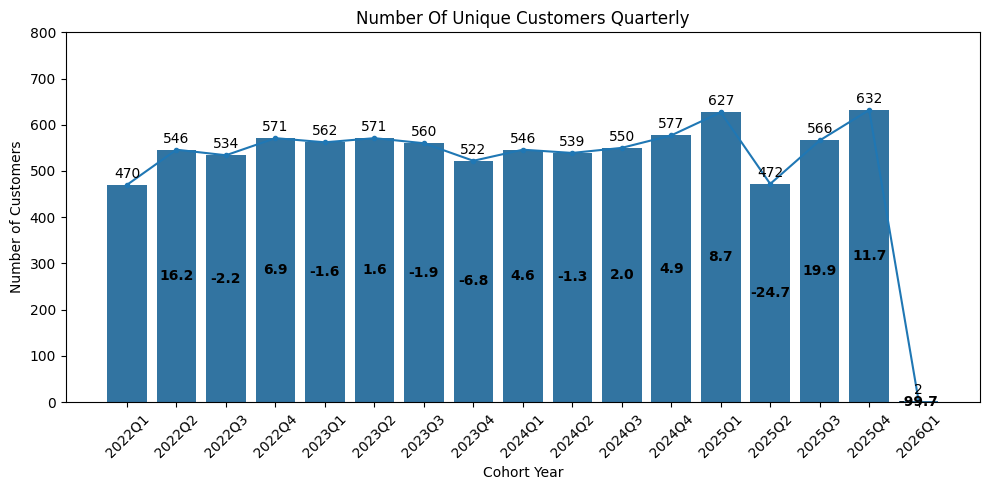

In [13]:
fig, ax = plt.subplots(figsize=(10,5))
ax = sns.barplot(data = quarter_cust, x='acquired_quarter',
                y='total_cust')

quarter_cust[['acquired_quarter', 'total_cust']].plot(kind='line',ax = ax, marker='.', legend=False)

# create percentage labels
pct_labels = [
    f"{val:.1f}" if pd.notna(val) else ""
    for i, val in enumerate(quarter_cust["percentage_increase"])
]

container = ax.containers[0]
      # display total customers
ax.bar_label(container, padding=3)

      # display percentage increase
ax.bar_label(
          container,
          labels=pct_labels,  # Pass a list with the single label for this bar
          label_type="center",
          color="black",
          fontweight="bold",
      )

plt.title('Number Of Unique Customers Quarterly')
plt.xlabel('Cohort Year')
plt.ylabel('Number of Customers')
plt.ylim(0,800)

ax.tick_params(axis='x', labelrotation=45)
plt.tight_layout()



* Number of new customers for each succeeding quarters are showing slow growth.
* There is a -24.7% drop in new customers in the 2nd quarter of 2025, but eventually returned to positive growth.
* First-quarter 2026 data is incomplete, containing order records exclusively for January 1, 2026

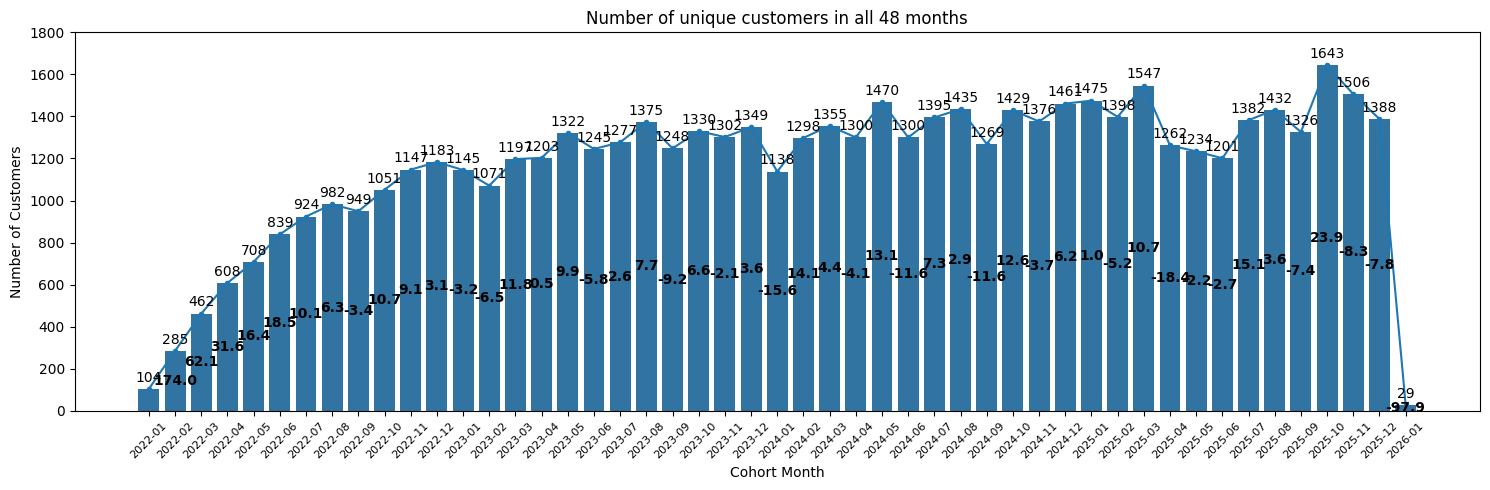

In [14]:
# count how many unique customers per month
monthly_cust = da.groupby('order_month', as_index=False)['customer_id'].nunique()
monthly_cust.columns = ['order_month', 'total_cust']
monthly_cust['percentage_increase'] = monthly_cust['total_cust'].pct_change() * 100


fig, ax1 = plt.subplots(figsize=(15,5))
ax1 = sns.barplot(data = monthly_cust, x='order_month',
                y='total_cust')

monthly_cust[['order_month', 'total_cust']].plot(kind='line',ax = ax1, marker='.', legend=False)

# create percentage labels
pct_labels = [
    f"{val:.1f}" if pd.notna(val) else ""
    for i, val in enumerate(monthly_cust["percentage_increase"])
]

container = ax1.containers[0]

    # display total customers
ax1.bar_label(container, padding=3)

    # display percentage increase
ax1.bar_label(
        container,
        labels=pct_labels,  # Pass a list with the single label for this bar
        label_type="center",
        color="black",
        fontweight="bold",
    )

plt.title('Number of unique customers in all 48 months')
plt.xlabel('Cohort Month')
plt.ylabel('Number of Customers')
plt.ylim(0,1800)

ax1.tick_params(axis='x', labelsize=8, labelrotation=45)
plt.tight_layout()



* Number of new customers showed a steady increase since the start of business in January 2022, which showed a positive business reaction.
* The increase slowed down starting in January 2023, but continued to grow gradually through the succeeding months.

# What percentage of customers were still engaging for each subsequent months, since their last order?

In [15]:
# computing retention rate

# get the first order month of the customers since 2022
da['cohort_month'] = da.groupby('customer_id')['order_month'].transform('min')
# monthly difference of the current order and the customers first order
da['month_diff'] = da['order_month'].dt.month - da['cohort_month'].dt.month
# yearly difference of the current order and the customers first order
da['year_diff'] = da['order_month'].dt.year - da['cohort_month'].dt.year

# cohort_index are months that passed since the customer's first order
# +1 to have the first displayed month index as "1" instead of "0"
da['cohort_index'] = da['year_diff'] * 12 + da['month_diff'] + 1


# group the first order month and months since first order
# and count each unique customers
cohort_data = (
    da.groupby(['cohort_month', 'cohort_index'])['customer_id']
.nunique().reset_index()
)

# pivot the data for easier analysis
cohort_matrix = cohort_data.pivot(
    index='cohort_month',
    columns='cohort_index',
    values='customer_id'
)

# get the number of unique customers for cohort index 1
cohort_size = cohort_matrix.iloc[:,0]

# divide each value by the value of month 1 to get percentage
retention_matrix = cohort_matrix.divide(cohort_size, axis=0) * 100


retention_matrix

cohort_index,1,2,3,4,5,6,7,8,9,10,...,39,40,41,42,43,44,45,46,47,48
cohort_month,,,,,,,,,,,,,,,,,,,,,
2022-01,100.0,100.000000,97.115385,83.653846,80.769231,74.038462,71.153846,63.461538,60.576923,50.961538,...,20.192308,15.384615,9.615385,13.461538,12.500000,13.461538,22.115385,13.461538,15.384615,17.307692
2022-02,100.0,97.237569,92.265193,82.320442,76.795580,71.270718,69.060773,62.430939,59.116022,58.563536,...,14.364641,19.337017,13.259669,16.574586,16.022099,14.917127,14.917127,16.022099,10.497238,0.552486
2022-03,100.0,87.567568,82.702703,79.459459,71.891892,74.594595,63.783784,57.837838,57.837838,51.891892,...,15.675676,14.594595,16.756757,15.135135,11.891892,14.594595,16.216216,15.675676,0.540541,NaN
2022-04,100.0,81.770833,78.645833,68.229167,71.354167,54.687500,56.250000,52.604167,52.083333,40.104167,...,13.020833,14.062500,13.541667,16.145833,18.750000,12.500000,15.104167,NaN,NaN,NaN
2022-05,100.0,82.424242,74.545455,69.696970,48.484848,56.363636,52.727273,50.303030,43.030303,36.363636,...,12.121212,16.363636,15.757576,15.757576,18.787879,12.121212,NaN,NaN,NaN,NaN
2022-06,100.0,71.428571,57.671958,52.910053,56.613757,57.671958,50.264550,46.560847,39.153439,41.798942,...,16.931217,12.698413,15.873016,10.582011,16.402116,1.058201,NaN,NaN,NaN,NaN
2022-07,100.0,67.336683,58.291457,51.758794,53.768844,48.241206,44.723618,40.703518,37.688442,40.201005,...,18.592965,19.095477,12.060302,14.572864,NaN,NaN,NaN,NaN,NaN,NaN
2022-08,100.0,48.734177,58.860759,50.000000,49.367089,55.063291,41.772152,37.974684,40.506329,37.974684,...,18.354430,13.924051,11.392405,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2022-09,100.0,58.757062,53.672316,50.847458,44.067797,36.158192,40.112994,38.418079,33.333333,35.028249,...,9.604520,12.429379,1.129944,NaN,NaN,NaN,NaN,NaN,NaN,NaN


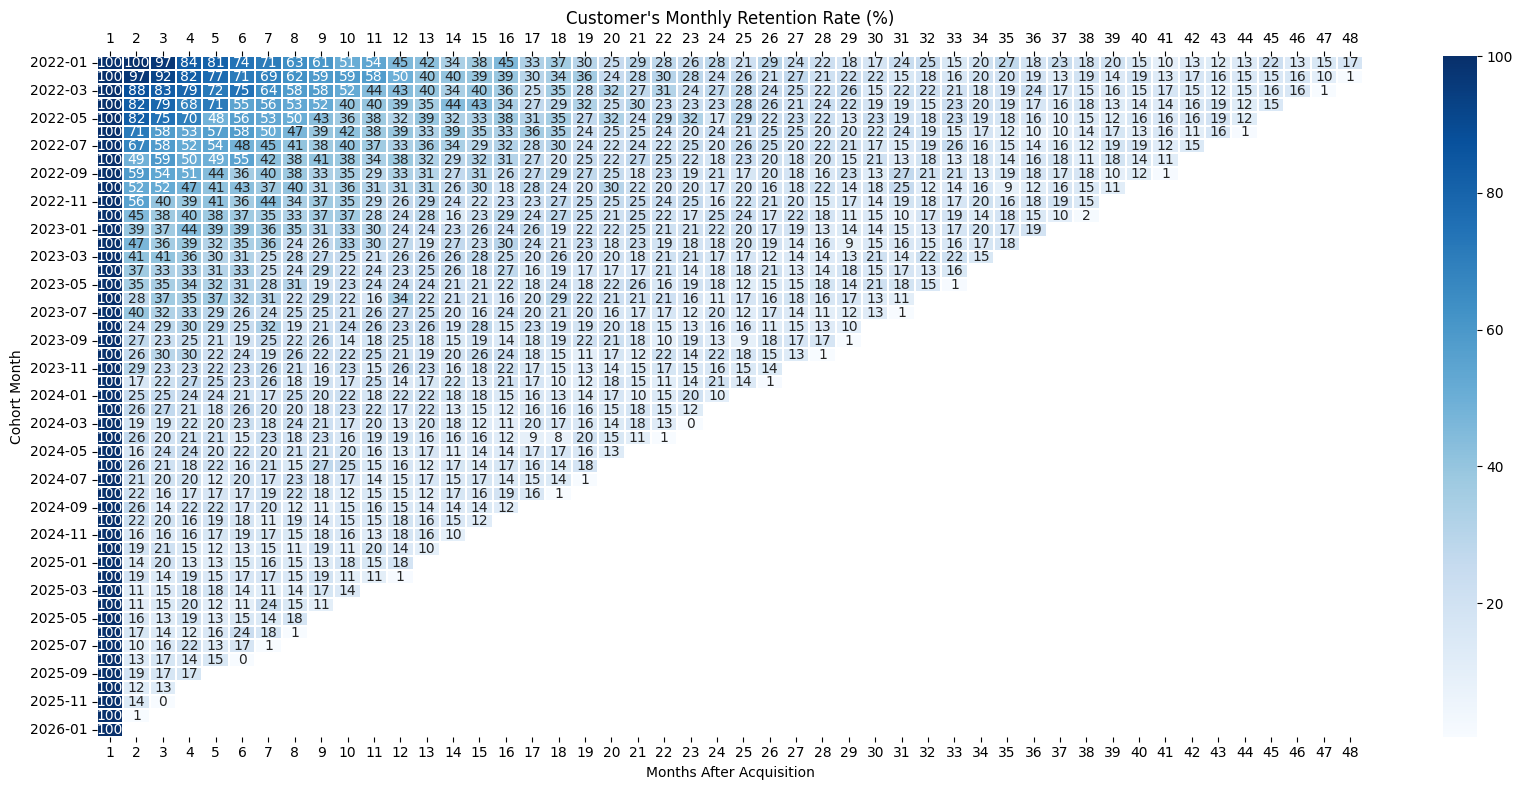

In [16]:
# visualize the retention matrix
plt.figure(figsize=(17, 8))
ax = sns.heatmap(
    retention_matrix,
    linewidths = 1.2,
    annot=True,
    fmt=".0f",
    cmap='Blues',
    vmin=retention_matrix.min(axis=None), # gets the min value anywhere in the pivot
    vmax=retention_matrix.iloc[:, 1:].max(axis=None), # gets the max value from month 2 onwards
)
plt.title("Customer's Monthly Retention Rate (%)")
plt.ylabel("Cohort Month")
plt.xlabel("Months After Acquisition")

ax.tick_params(
    axis='x',
    top=True,
    labeltop=True,
    bottom=True,
    labelbottom=True
)
plt.tight_layout()

The plot shows how many customers remained engaged for the subsequent months since the first month they started engaging.
* Engagement rates begin to decline after acquisition.
* We could assume that the popularity of the business during their inception was high because of customers hype chasing behavior.
* 2022 cohorts kept 45 to 97% into month 2.
* 2024 and 2025 cohorts only kept 11% to 26% into month 2.
* We could also assume that the popularity of the business is declining dramatically due to operational issues or customer preferences.
* Although the number of new customers showed growth over time the churn rate for these customers are high.



# Customer retention rate by menu items

In [17]:
menu_orders_df = orders[['order_id', 'order_date','customer_id',
                         'order', 'order_category','age',
                         'part_of_day','income','payment_method','gender']]
menu_orders_df['order_date'] = pd.to_datetime(menu_orders_df['order_date'], format = "%Y-%m-%d")
menu_orders_df['order_month'] = menu_orders_df['order_date'].dt.to_period('M')

menu_orders_df

,order_id,order_date,customer_id,order,order_category,age,part_of_day,income,payment_method,gender,order_month
99213,ORD-67560,2022-01-02,b95e44e3,Americano,Drinks,51,evening,29100.0,Cash,Female,2022-01
137933,ORD-939323,2022-01-02,b95e44e3,Caldereta,Meal,51,afternoon,29100.0,Cash,Female,2022-01
137932,ORD-939323,2022-01-02,b95e44e3,Burger Steak,Meal,51,afternoon,29100.0,Cash,Female,2022-01
3798,ORD-025992,2022-01-02,b95e44e3,Kare-Kare,Meal,51,afternoon,29100.0,Card,Female,2022-01
99214,ORD-67560,2022-01-02,b95e44e3,Caldereta,Meal,51,evening,29100.0,Cash,Female,2022-01
...,...,...,...,...,...,...,...,...,...,...,...
71841,ORD-489327,2026-01-01,1ccc33c1,Carbonara,Meal,58,evening,20800.0,Cash,Female,2026-01
109466,ORD-74579,2026-01-01,d00dcc4f,Barista's Drink,Drinks,45,evening,41700.0,Cash,Female,2026-01
63378,ORD-430839,2026-01-01,7f53d344,Spaghetti Bolognese,Meal,44,evening,40600.0,Cash,Female,2026-01
137072,ORD-933678,2026-01-01,02b3c948,Carbonara,Meal,37,evening,24200.0,Cash,Female,2026-01


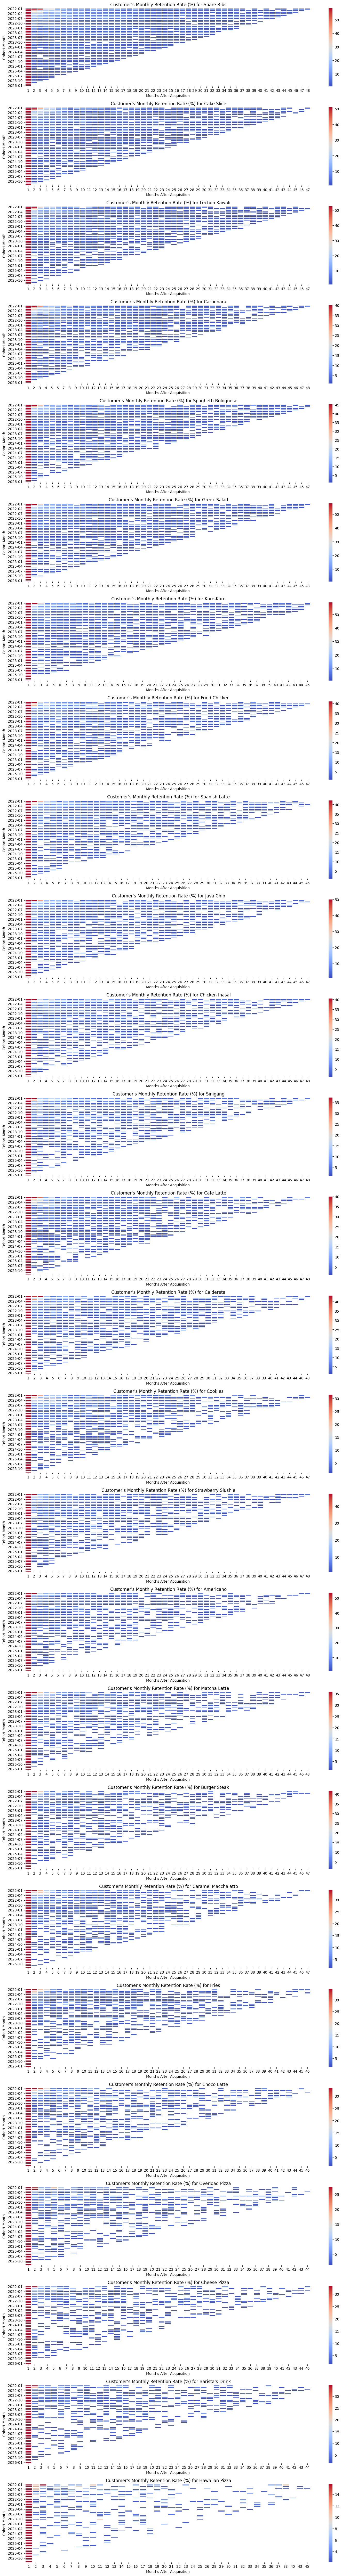

In [18]:
fig, axes = plt.subplots(nrows=26, ncols=1, figsize=(15,100))
ax = axes.flatten()
for i,cat in enumerate(menu_orders_df['order'].value_counts().index):
    # spicify the menu item
    category = cat
    menu_orders = menu_orders_df.query('order == @category')

    #get the first month that the menu was ordered
    menu_orders['cohort_month'] = menu_orders.groupby('customer_id')['order_month'].transform('min')
    # compute cohort_index which tells how long has it been since the menu item was ordered
    # by subtracting the current month to the first month it was ordered.
    menu_orders['month_diff'] = (menu_orders['order_month'].dt.month - menu_orders['cohort_month'].dt.month)
    menu_orders['year_diff'] = (menu_orders['order_month'].dt.year - menu_orders['cohort_month'].dt.year)
    menu_orders['cohort_index'] = menu_orders['year_diff'] * 12 + menu_orders['month_diff'] + 1

    # group the menu orders by the cohort index and cohort month get the number of customers who ordered for those months.
    cohort_data = menu_orders.groupby(['cohort_month', 'cohort_index'])['customer_id'].nunique().reset_index()

    # pivot the data
    cohort_matrix = cohort_data.pivot(
        index='cohort_month', columns='cohort_index', values='customer_id'
    )
    # get the 1st month
    cohort_size = cohort_matrix.iloc[:,0]
    # divide each value by the value of 1st month
    retention_matrix = cohort_matrix.divide(cohort_size, axis=0) * 100

    # plot heatmap
    sns.heatmap(
        retention_matrix,
        linewidths=0.9,
        fmt=".1f",
        cmap="coolwarm",
        vmin=retention_matrix.min(axis=None), # gets the min value anywhere in the pivot
        vmax=retention_matrix.iloc[:, 1:].max(axis=None), # gets the max value from month 2 onwards

        ax = ax[i]
    )
    ax[i].set_title(f" Customer's Monthly Retention Rate (%) for {category}")
    ax[i].set_ylabel("Cohort Month")
    ax[i].set_xlabel("Months After Acquisition")

plt.tight_layout()



The plot shows how each of menu items are still being ordered subsequently after they are first observed.
For example, if Hawaiian Pizza was first ordered in January 2022, How many customers who ordered Hawaiian Pizza from January 2022 still ordered in the following months?
* Certain menu items had great drops in customer retention rate indicating declining preferability.
* Cheese Pizza, Barista's Drink, and Hawaiian Pizza are all showing sparse and low retention rates since inception.
* Improving or discontinuing these menu items is recommended to minimize ingredient waste and optimize resource utilization.

# Customer retention rate by order category

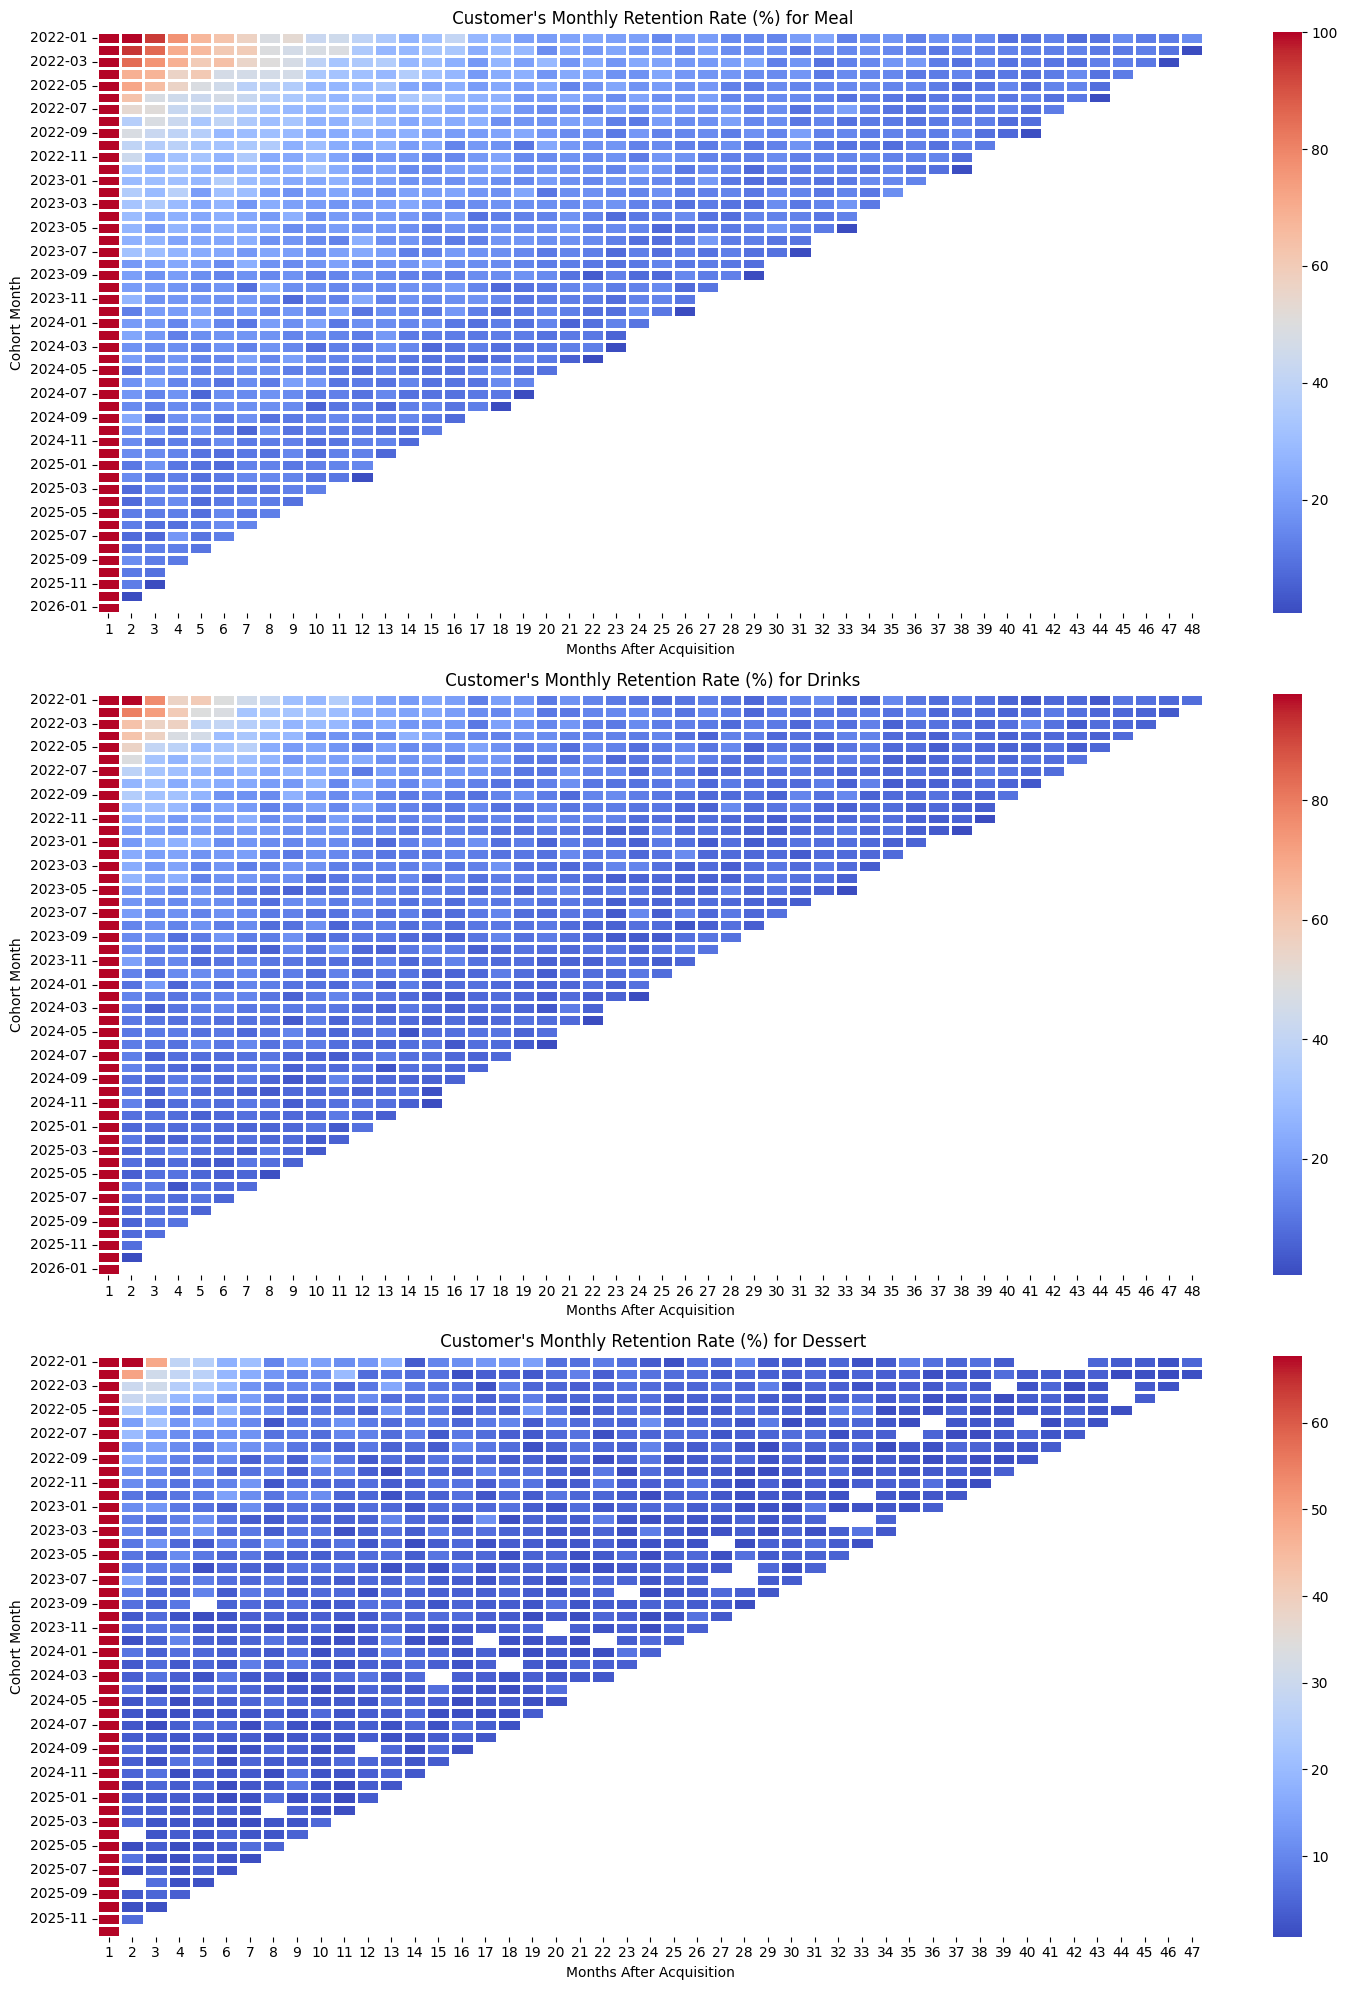

In [19]:

fig, axes = plt.subplots(nrows=3, ncols=1, figsize=(15,20))
ax = axes.flatten()
for i,cat in enumerate(menu_orders_df['order_category'].value_counts().index):
    # spicify the order category
    category = cat
    menu_orders = menu_orders_df.query('order_category == @category')

    #get the first month that the customer ordered
    menu_orders['cohort_month'] = menu_orders.groupby('customer_id')['order_month'].transform('min')
    menu_orders['month_diff'] = (menu_orders['order_month'].dt.month - menu_orders['cohort_month'].dt.month)
    menu_orders['year_diff'] = (menu_orders['order_month'].dt.year - menu_orders['cohort_month'].dt.year)
    menu_orders['cohort_index'] = menu_orders['year_diff'] * 12 + menu_orders['month_diff'] + 1

    # group the menu orders by the cohort index and cohort month get the number of customers who ordered for those months.
    cohort_data = menu_orders.groupby(['cohort_month', 'cohort_index'])['customer_id'].nunique().reset_index()

    # pivot the data
    cohort_matrix = cohort_data.pivot(
        index='cohort_month', columns='cohort_index', values='customer_id'
    )
    # get the 1st month
    cohort_size = cohort_matrix.iloc[:,0]
    # divide each value by the value of 1st month
    retention_matrix = cohort_matrix.divide(cohort_size, axis=0) * 100



    # plot heatmap
    sns.heatmap(
        retention_matrix,
        linewidths=0.9,
        fmt=".1f",
        cmap="coolwarm",
        vmin=retention_matrix.min(axis=None), # gets the min value anywhere in the pivot
        vmax=retention_matrix.iloc[:, 1:].max(axis=None), # gets the max value from month 2 onwards
        ax = ax[i]
    )
    ax[i].set_title(f" Customer's Monthly Retention Rate (%) for {category}")
    ax[i].set_ylabel("Cohort Month")
    ax[i].set_xlabel("Months After Acquisition")

plt.tight_layout()



* Meals showed the highest retention, followed by drinks and dessert.
* Each order category is diminishing in engagement over time.
* Dessert showed sparse retention rates. But since it only has 2 menu items (Cake Slice & Cookies), popularity declines due to lack of choices for dessert.

# Customer retention by age group

In [20]:
menu_orders_df.head()

,order_id,order_date,customer_id,order,order_category,age,part_of_day,income,payment_method,gender,order_month
99213,ORD-67560,2022-01-02,b95e44e3,Americano,Drinks,51,evening,29100.0,Cash,Female,2022-01
137933,ORD-939323,2022-01-02,b95e44e3,Caldereta,Meal,51,afternoon,29100.0,Cash,Female,2022-01
137932,ORD-939323,2022-01-02,b95e44e3,Burger Steak,Meal,51,afternoon,29100.0,Cash,Female,2022-01
3798,ORD-025992,2022-01-02,b95e44e3,Kare-Kare,Meal,51,afternoon,29100.0,Card,Female,2022-01
99214,ORD-67560,2022-01-02,b95e44e3,Caldereta,Meal,51,evening,29100.0,Cash,Female,2022-01


In [21]:
# bin the age into detailed age groups
menu_orders_df['detailed_age_group'] = pd.cut(
    menu_orders_df['age'],
    bins = [17,24,44,59,74,np.inf],
    labels = ['Youth (17-24 years)', 'Young Adults (25-44 years)',
              'Middle Age (45-59 years)', 'Elderly (60-74 years)', 'Senior (75-90 years)']
                         )

menu_orders_df['detailed_age_group'].value_counts()

,count
detailed_age_group,
Young Adults (25-44 years),86473
Middle Age (45-59 years),36331
Elderly (60-74 years),11924
Youth (17-24 years),8008
Senior (75-90 years),4326


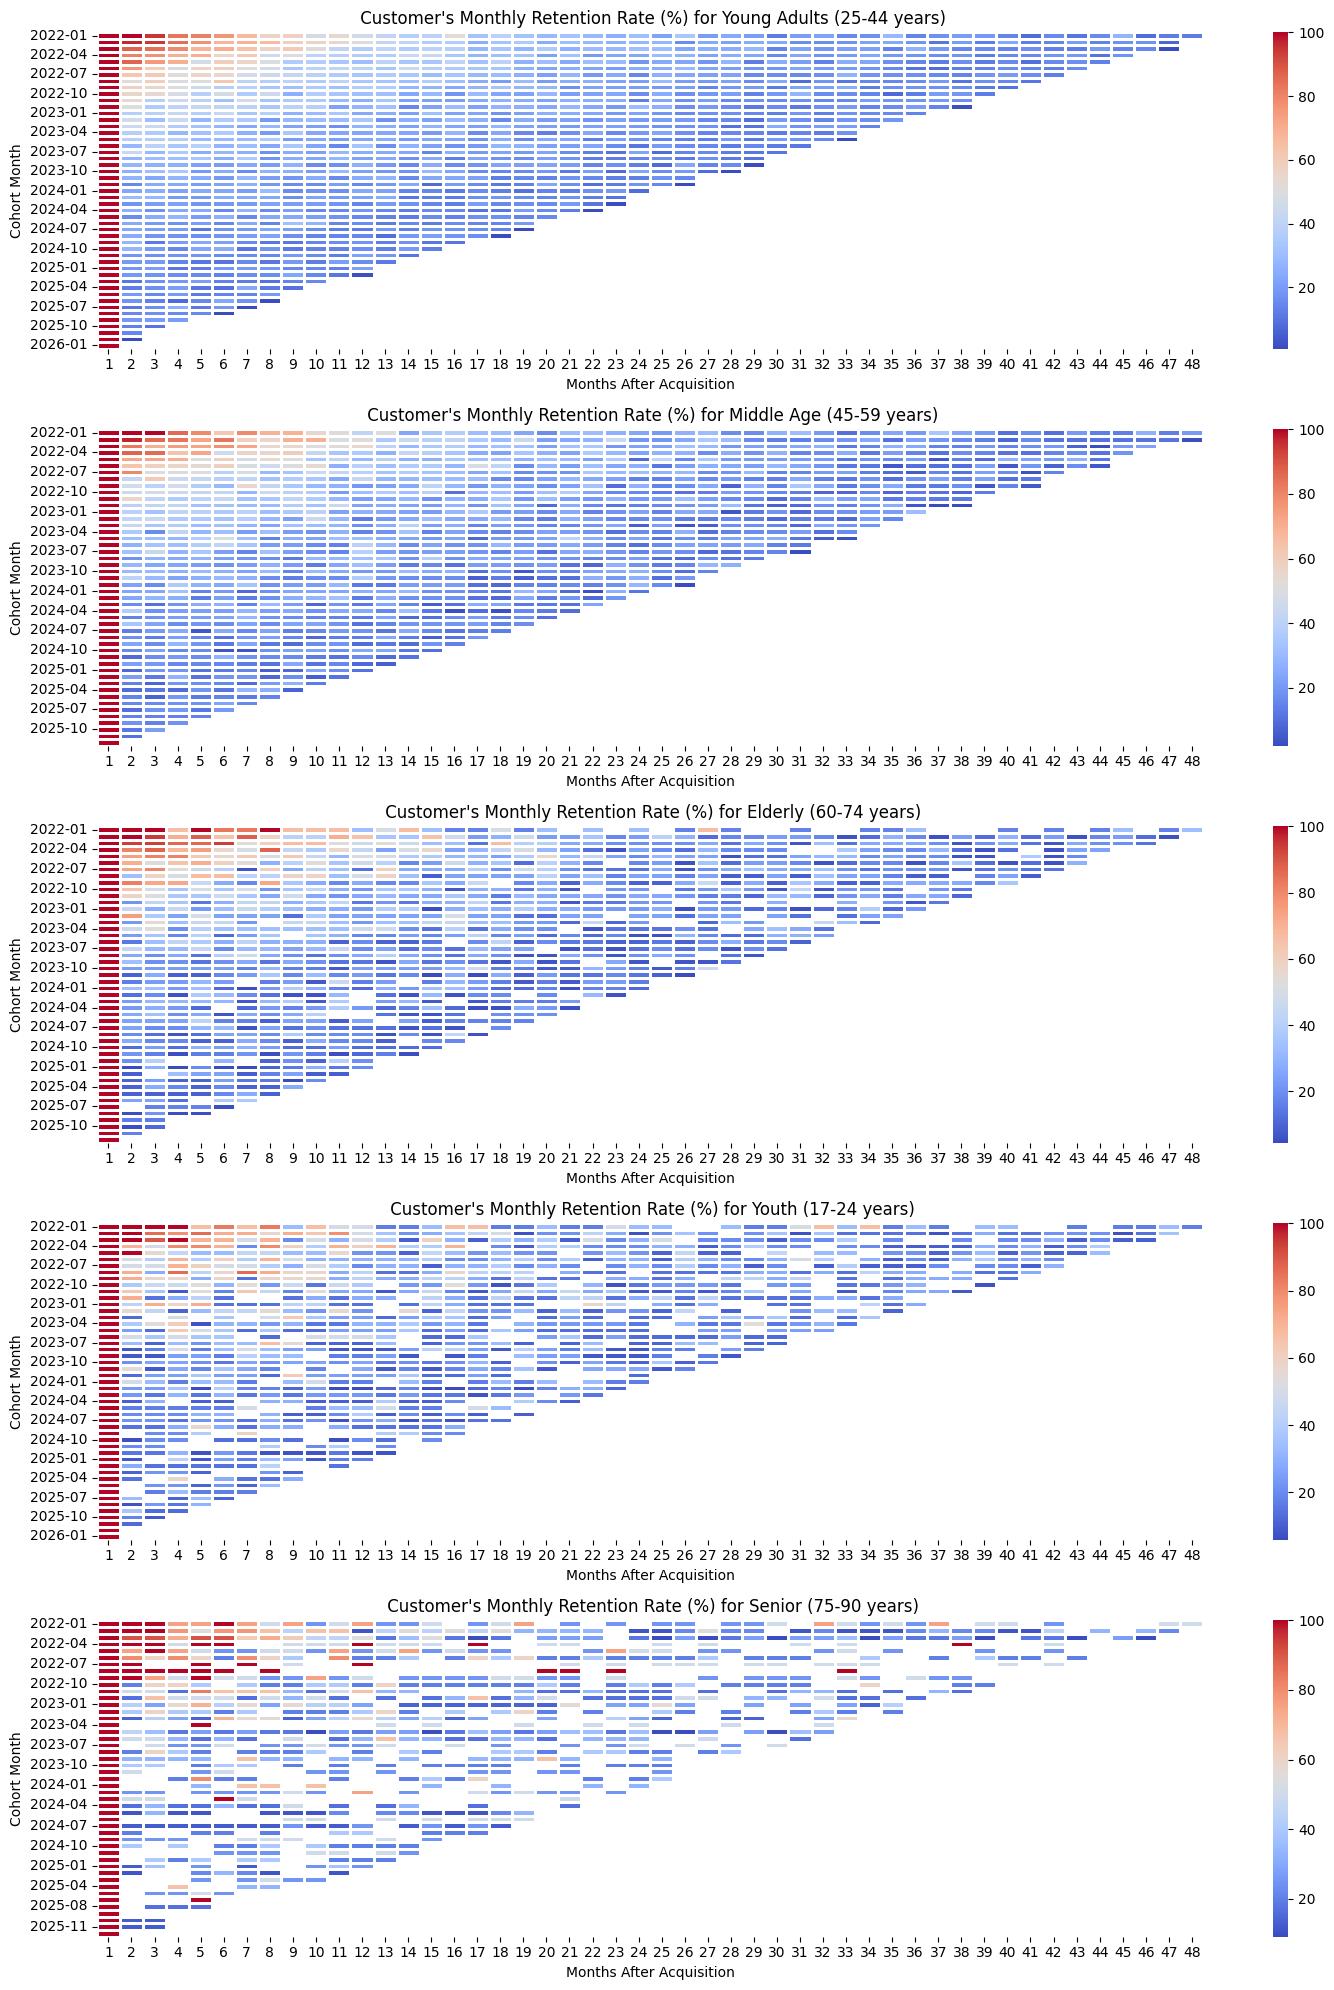

In [22]:
fig, axes = plt.subplots(nrows=5, ncols=1, figsize=(15,20))
ax = axes.flatten()
for i,group in enumerate(menu_orders_df['detailed_age_group'].value_counts().index):
    # spicify the order category
    age_group = group
    menu_orders = menu_orders_df.query('detailed_age_group == @age_group')

    #get the first month that the customer ordered
    menu_orders['cohort_month'] = menu_orders.groupby('customer_id')['order_month'].transform('min')
    menu_orders['month_diff'] = (menu_orders['order_month'].dt.month - menu_orders['cohort_month'].dt.month)
    menu_orders['year_diff'] = (menu_orders['order_month'].dt.year - menu_orders['cohort_month'].dt.year)
    menu_orders['cohort_index'] = menu_orders['year_diff'] * 12 + menu_orders['month_diff'] + 1

    # group the menu orders by the cohort index and cohort month get the number of customers who ordered for those months.
    cohort_data = menu_orders.groupby(['cohort_month', 'cohort_index'])['customer_id'].nunique().reset_index()

    # pivot the data
    cohort_matrix = cohort_data.pivot(
        index='cohort_month', columns='cohort_index', values='customer_id'
    )
    # get the 1st month
    cohort_size = cohort_matrix.iloc[:,0]
    # divide each value by the value of 1st month
    retention_matrix = cohort_matrix.divide(cohort_size, axis=0) * 100



    # plot heatmap
    sns.heatmap(
        retention_matrix,
        linewidths=0.9,
        fmt=".1f",
        cmap="coolwarm",
        vmin=retention_matrix.min(axis=None), # gets the min value anywhere in the pivot
        vmax=retention_matrix.iloc[:, 1:].max(axis=None), # gets the max value from month 2 onwards
        ax = ax[i]
    )
    ax[i].set_title(f" Customer's Monthly Retention Rate (%) for {age_group}")
    ax[i].set_ylabel("Cohort Month")
    ax[i].set_xlabel("Months After Acquisition")

plt.tight_layout()



* Sparse engagement rates are observed for Seniors aged 75 to 90 years old, however they have high engagement rate values after acquisition which somehow compensates for the thin retention rates in certain months.
* Engagement rates across all age is diminishing over time.

# Customer Retention by gender

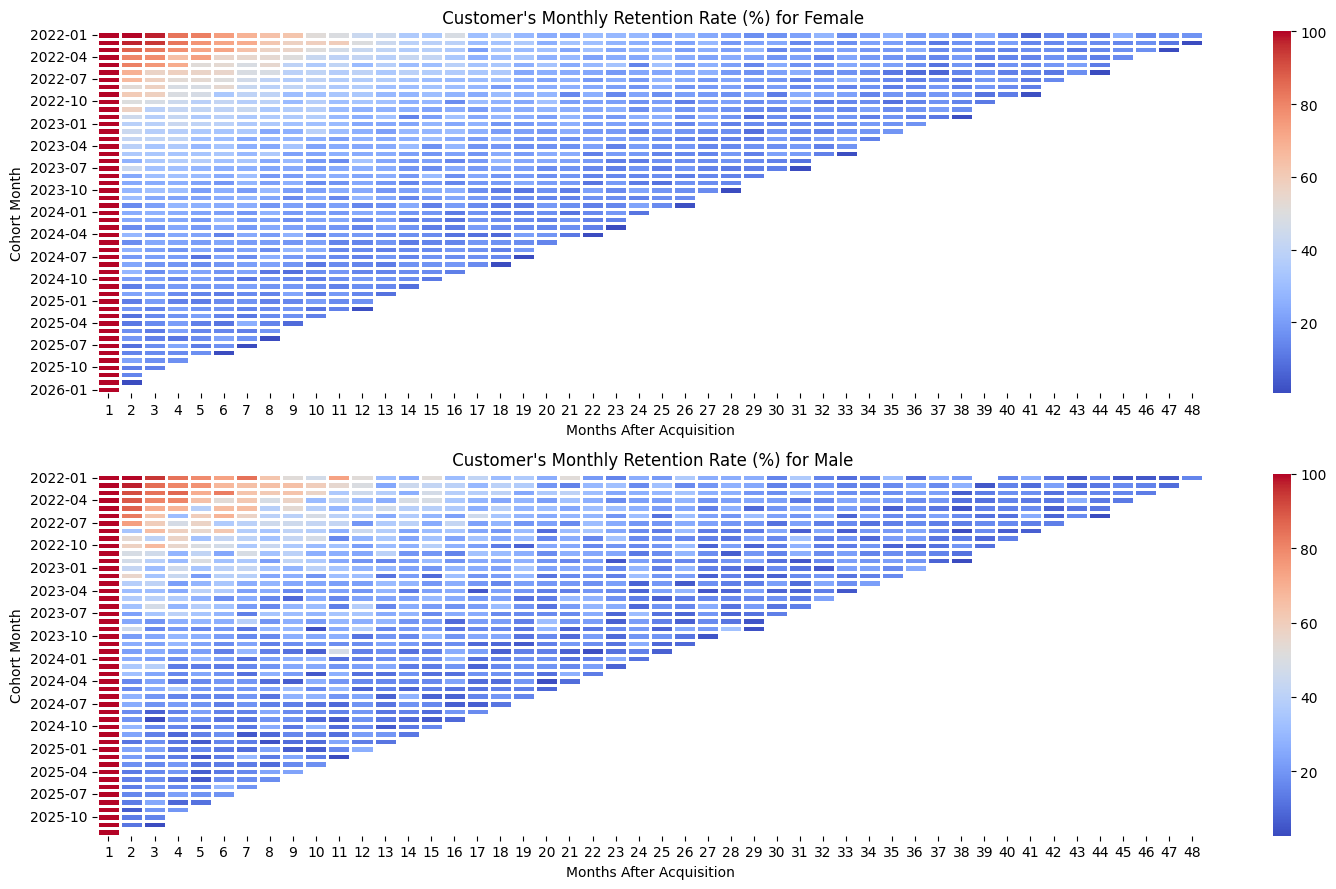

In [23]:
fig, axes = plt.subplots(nrows=2, ncols=1, figsize=(15,9))
ax = axes.flatten()
for i,group in enumerate(menu_orders_df['gender'].value_counts().index):
    # spicify the order category
    gender = group
    menu_orders = menu_orders_df.query('gender == @gender')

    #get the first month that the customer ordered
    menu_orders['cohort_month'] = menu_orders.groupby('customer_id')['order_month'].transform('min')
    menu_orders['month_diff'] = (menu_orders['order_month'].dt.month - menu_orders['cohort_month'].dt.month)
    menu_orders['year_diff'] = (menu_orders['order_month'].dt.year - menu_orders['cohort_month'].dt.year)
    menu_orders['cohort_index'] = menu_orders['year_diff'] * 12 + menu_orders['month_diff'] + 1

    # group the menu orders by the cohort index and cohort month get the number of customers who ordered for those months.
    cohort_data = menu_orders.groupby(['cohort_month', 'cohort_index'])['customer_id'].nunique().reset_index()

    # pivot the data
    cohort_matrix = cohort_data.pivot(
        index='cohort_month', columns='cohort_index', values='customer_id'
    )
    # get the 1st month
    cohort_size = cohort_matrix.iloc[:,0]
    # divide each value by the value of 1st month
    retention_matrix = cohort_matrix.divide(cohort_size, axis=0) * 100



    # plot heatmap
    sns.heatmap(
        retention_matrix,
        linewidths=0.9,
        fmt=".1f",
        cmap="coolwarm",
        vmin=retention_matrix.min(axis=None), # gets the min value anywhere in the pivot
        vmax=retention_matrix.iloc[:, 1:].max(axis=None), # gets the max value from month 2 onwards
        ax = ax[i]
    )
    ax[i].set_title(f" Customer's Monthly Retention Rate (%) for {gender}")
    ax[i].set_ylabel("Cohort Month")
    ax[i].set_xlabel("Months After Acquisition")

plt.tight_layout()



* Both gender declines in engagement over time.

# Customer retention by part of the day

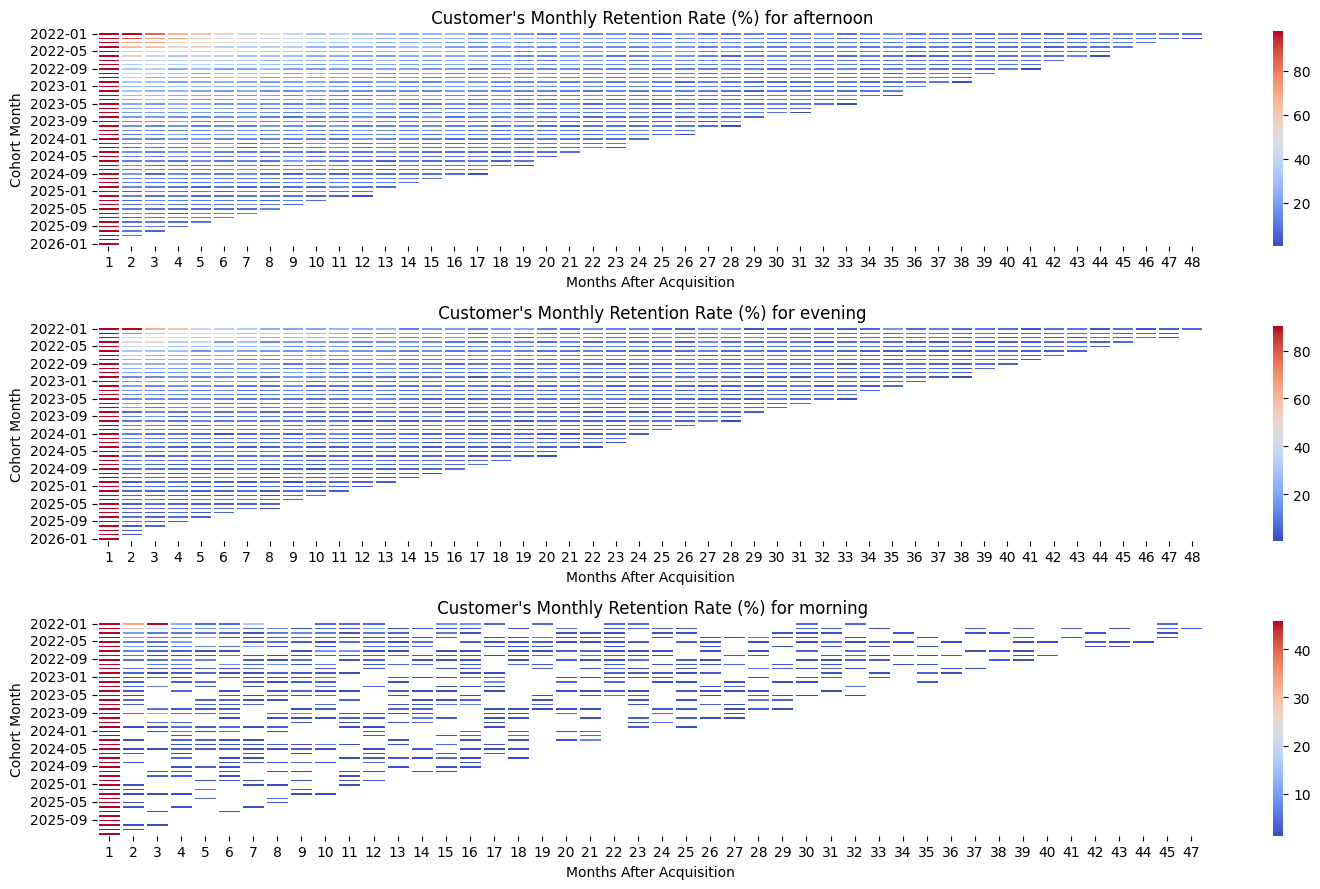

In [24]:
fig, axes = plt.subplots(nrows=3, ncols=1, figsize=(15,9))
ax = axes.flatten()
for i,group in enumerate(menu_orders_df['part_of_day'].value_counts().index):
    # spicify the order category
    part_of_day = group
    menu_orders = menu_orders_df.query('part_of_day == @part_of_day')

    #get the first month that the customer ordered
    menu_orders['cohort_month'] = menu_orders.groupby('customer_id')['order_month'].transform('min')
    menu_orders['month_diff'] = (menu_orders['order_month'].dt.month - menu_orders['cohort_month'].dt.month)
    menu_orders['year_diff'] = (menu_orders['order_month'].dt.year - menu_orders['cohort_month'].dt.year)
    menu_orders['cohort_index'] = menu_orders['year_diff'] * 12 + menu_orders['month_diff'] + 1

    # group the menu orders by the cohort index and cohort month get the number of customers who ordered for those months.
    cohort_data = menu_orders.groupby(['cohort_month', 'cohort_index'])['customer_id'].nunique().reset_index()

    # pivot the data
    cohort_matrix = cohort_data.pivot(
        index='cohort_month', columns='cohort_index', values='customer_id'
    )
    # get the 1st month
    cohort_size = cohort_matrix.iloc[:,0]
    # divide each value by the value of 1st month
    retention_matrix = cohort_matrix.divide(cohort_size, axis=0) * 100



    # plot heatmap
    sns.heatmap(
        retention_matrix,
        linewidths=0.9,
        fmt=".1f",
        cmap="coolwarm",
        vmin=retention_matrix.min(axis=None), # gets the min value anywhere in the pivot
        vmax=retention_matrix.iloc[:, 1:].max(axis=None), # gets the max value from month 2 onwards
        ax = ax[i]
    )
    ax[i].set_title(f" Customer's Monthly Retention Rate (%) for {part_of_day}")
    ax[i].set_ylabel("Cohort Month")
    ax[i].set_xlabel("Months After Acquisition")

plt.tight_layout()



* There are no significant differences in all parts of the day retention rate.
* Morning retention rate showing sparse outputs because it only represents 1 hour (11 am) of the overall business hours.

# Customer retention by payment method

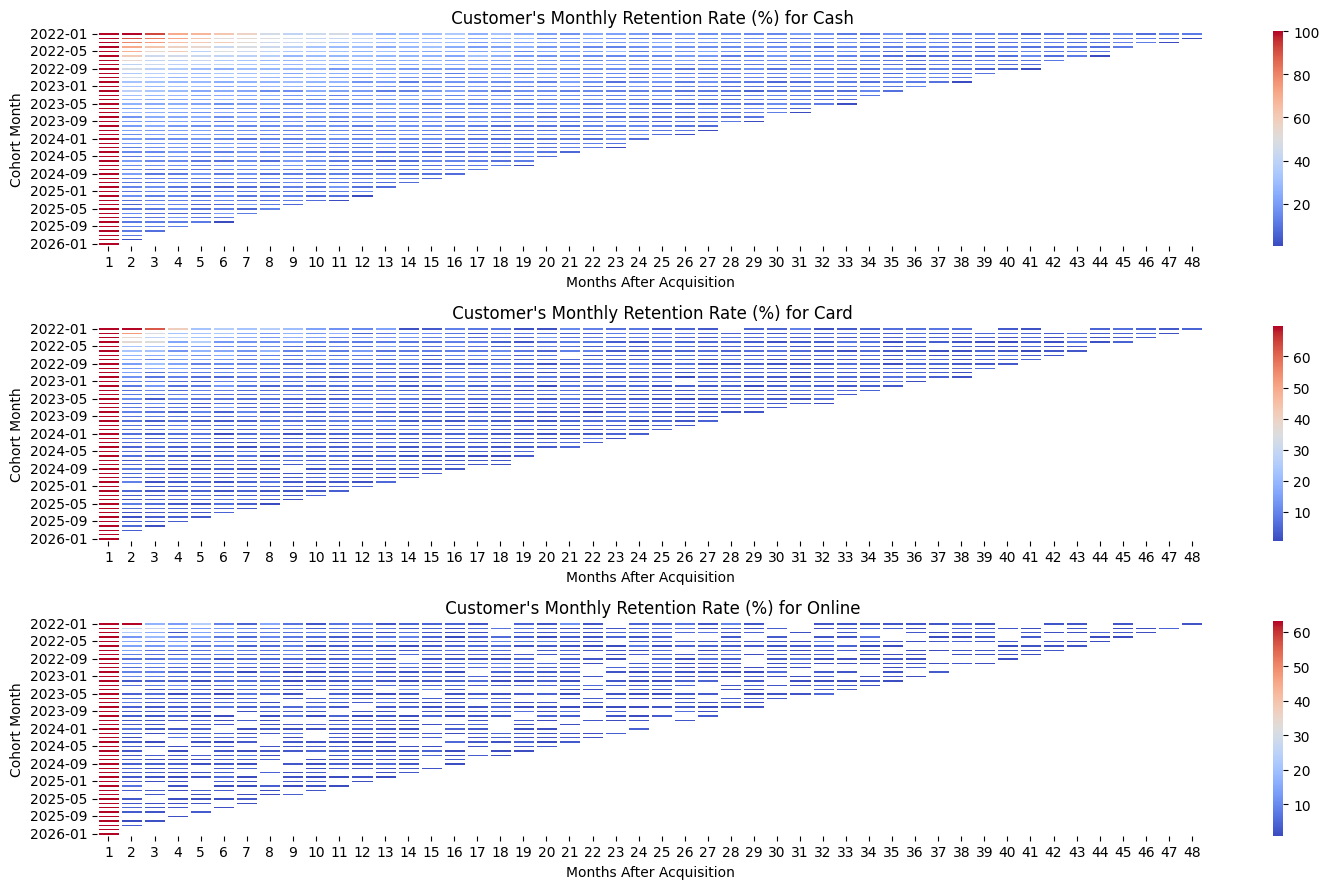

In [25]:
fig, axes = plt.subplots(nrows=3, ncols=1, figsize=(15,9))
ax = axes.flatten()
for i,group in enumerate(menu_orders_df['payment_method'].value_counts().index):
    # spicify the order category
    payment_method = group
    menu_orders = menu_orders_df.query('payment_method == @payment_method')

    #get the first month that the customer ordered
    menu_orders['cohort_month'] = menu_orders.groupby('customer_id')['order_month'].transform('min')
    menu_orders['month_diff'] = (menu_orders['order_month'].dt.month - menu_orders['cohort_month'].dt.month)
    menu_orders['year_diff'] = (menu_orders['order_month'].dt.year - menu_orders['cohort_month'].dt.year)
    menu_orders['cohort_index'] = menu_orders['year_diff'] * 12 + menu_orders['month_diff'] + 1

    # group the menu orders by the cohort index and cohort month get the number of customers who ordered for those months.
    cohort_data = menu_orders.groupby(['cohort_month', 'cohort_index'])['customer_id'].nunique().reset_index()

    # pivot the data
    cohort_matrix = cohort_data.pivot(
        index='cohort_month', columns='cohort_index', values='customer_id'
    )
    # get the 1st month
    cohort_size = cohort_matrix.iloc[:,0]
    # divide each value by the value of 1st month
    retention_matrix = cohort_matrix.divide(cohort_size, axis=0) * 100



    # plot heatmap
    sns.heatmap(
        retention_matrix,
        linewidths=0.9,
        fmt=".1f",
        cmap="coolwarm",
        vmin=retention_matrix.min(axis=None), # gets the min value anywhere in the pivot
        vmax=retention_matrix.iloc[:, 1:].max(axis=None), # gets the max value from month 2 onwards
        ax = ax[i]
    )
    ax[i].set_title(f" Customer's Monthly Retention Rate (%) for {payment_method}")
    ax[i].set_ylabel("Cohort Month")
    ax[i].set_xlabel("Months After Acquisition")

plt.tight_layout()



* Retention rates for payment types all decline over time.
* Cash payment remained consistent with no visible sparse months.

# Customer retention by income category

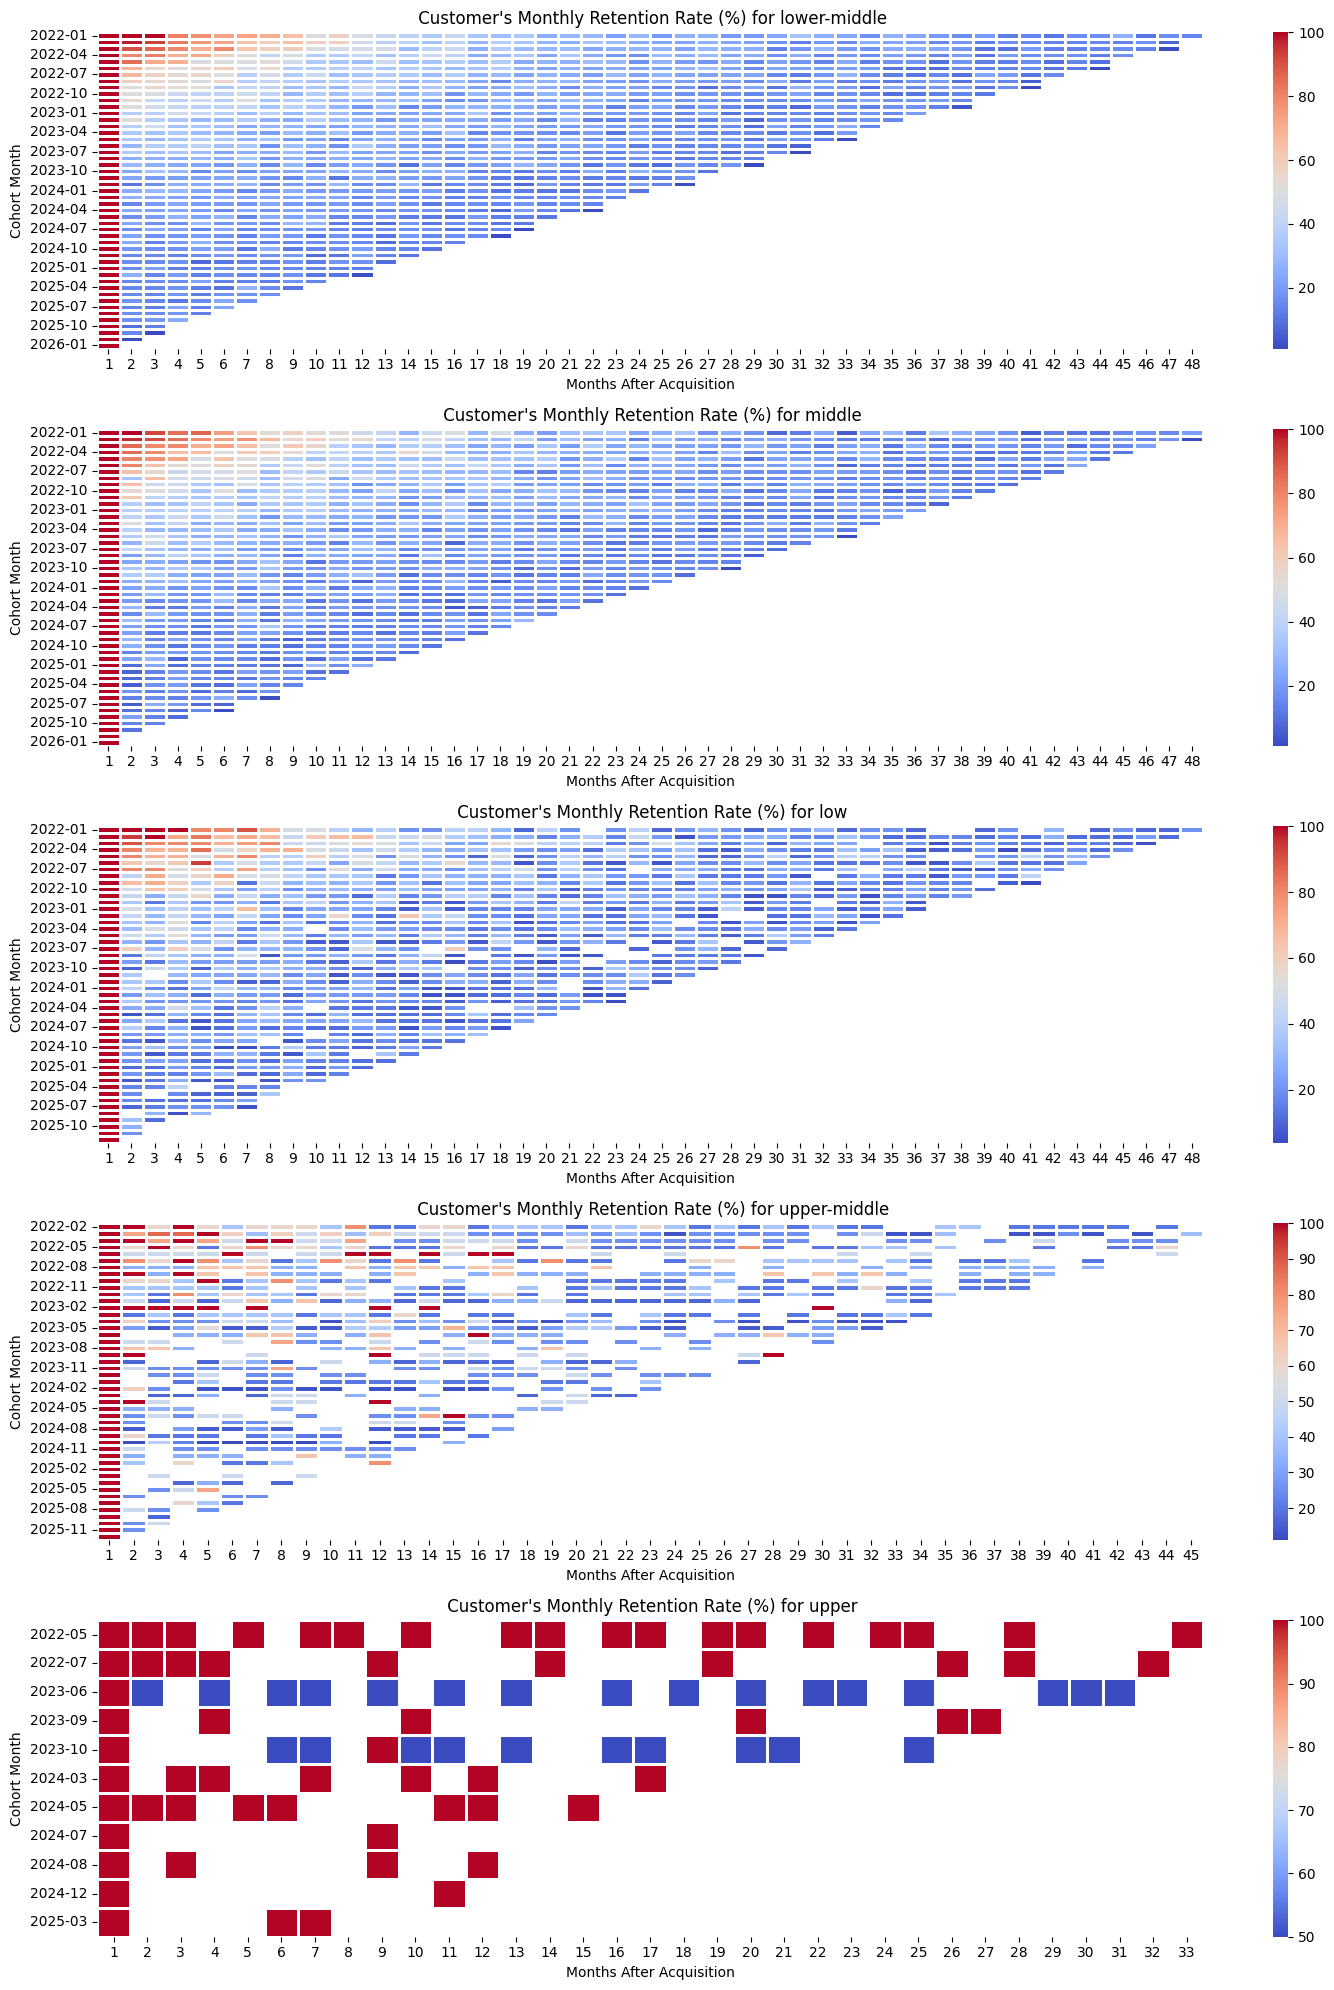

In [26]:
menu_orders_df['income_cat'] = pd.cut(
    menu_orders_df['income'], bins=[-np.inf, 15_000, 30_000, 60_000, 90_000, np.inf ],
    labels = ['low', 'lower-middle', 'middle', 'upper-middle', 'upper']
)
menu_orders_df['income_cat'].value_counts()


fig, axes = plt.subplots(nrows=5, ncols=1, figsize=(15,20))
ax = axes.flatten()
for i,group in enumerate(menu_orders_df['income_cat'].value_counts().index):
    # spicify the order category
    income_cat = group
    menu_orders = menu_orders_df.query('income_cat == @income_cat')

    #get the first month that the customer ordered
    menu_orders['cohort_month'] = menu_orders.groupby('customer_id')['order_month'].transform('min')
    menu_orders['month_diff'] = (menu_orders['order_month'].dt.month - menu_orders['cohort_month'].dt.month)
    menu_orders['year_diff'] = (menu_orders['order_month'].dt.year - menu_orders['cohort_month'].dt.year)
    menu_orders['cohort_index'] = menu_orders['year_diff'] * 12 + menu_orders['month_diff'] + 1

    # group the menu orders by the cohort index and cohort month get the number of customers who ordered for those months.
    cohort_data = menu_orders.groupby(['cohort_month', 'cohort_index'])['customer_id'].nunique().reset_index()

    # pivot the data
    cohort_matrix = cohort_data.pivot(
        index='cohort_month', columns='cohort_index', values='customer_id'
    )
    # get the 1st month
    cohort_size = cohort_matrix.iloc[:,0]
    # divide each value by the value of 1st month
    retention_matrix = cohort_matrix.divide(cohort_size, axis=0) * 100



    # plot heatmap
    sns.heatmap(
        retention_matrix,
        linewidths=0.9,
        fmt=".1f",
        cmap="coolwarm",
        vmin=retention_matrix.min(axis=None), # gets the min value anywhere in the pivot
        vmax=retention_matrix.iloc[:, 1:].max(axis=None), # gets the max value from month 2 onwards
        ax = ax[i]
    )
    ax[i].set_title(f" Customer's Monthly Retention Rate (%) for {income_cat}")
    ax[i].set_ylabel("Cohort Month")
    ax[i].set_xlabel("Months After Acquisition")

plt.tight_layout()



* Retention rates for upper class salary (90,000 pesos and above) has sparse engagements and incomplete months, however most of the customers who started to join has a high rate of retention from 50% to 100%.
* Upper middle class salary (60,000 to 90,000 pesos) also showed sparse engagements but high rate of retention even on succeeding months with 40% to 100% are well observed.
* Other income class showed consistency but diminishing engagements over time.
* This shows that customers having a high salary grade (60k and above) are the minority in terms of income group, but tends to stay engaged even after a few years.

# How much revenue each monthly customer cohort generates over time on a cumulative per-customer basis?

In [27]:
pay_df = orders[['order_date','customer_id','Price']]

pay_df['first_purchase_month'] = (pay_df.groupby('customer_id')['order_date'].transform('min').dt.to_period('M'))

pay_df['transaction_month'] = (pay_df['order_date'].dt.to_period('M'))

# compute month index
year_diff = pay_df['transaction_month'].dt.year - pay_df['first_purchase_month'].dt.year
month_diff = pay_df['transaction_month'].dt.month - pay_df['first_purchase_month'].dt.month
pay_df['month_index'] = year_diff * 12 + month_diff + 1

# create matrix
rev_matrix = pay_df.pivot_table(
    index = 'first_purchase_month',
    columns = 'month_index',
    values = 'Price',
    aggfunc = 'sum'
)

cohort_sizes = pay_df.groupby('first_purchase_month')['customer_id'].nunique()

cumulative_rev = rev_matrix.cumsum(axis=1) # cumsum shows the progression of revenue over time
ltv_matrix = cumulative_rev.divide(cohort_sizes, axis=0) # cumulative lifetime value over time,
# by dividing it with the cohort size we get how much does a single customer generates cumulative revenue averagely




In [28]:
ltv_matrix

month_index,1,2,3,4,5,6,7,8,9,10,...,39,40,41,42,43,44,45,46,47,48
first_purchase_month,,,,,,,,,,,,,,,,,,,,,
2022-01,6605.413462,10208.076923,12071.192308,13022.586538,13899.596154,14555.538462,15083.211538,15515.884615,15896.115385,16233.048077,...,21328.942308,21381.326923,21444.394231,21541.932692,21593.942308,21682.259615,21786.932692,21876.009615,21952.048077,22032.230769
2022-02,2098.613260,3898.740331,5054.773481,5970.740331,6640.209945,7281.977901,7793.834254,8238.823204,8638.850829,9018.679558,...,13779.033149,13863.182320,13940.745856,14043.817680,14127.375691,14209.977901,14307.546961,14402.839779,14438.767956,14440.480663
2022-03,1220.108108,2402.259459,3308.745946,4048.945946,4624.659459,5297.578378,5802.724324,6241.718919,6671.032432,6965.118919,...,11429.345946,11518.589189,11602.086486,11698.329730,11765.529730,11825.756757,11908.800000,11989.583784,11990.745946,NaN
2022-04,1106.942708,2060.687500,2875.343750,3428.072917,3990.109375,4381.937500,4822.510417,5222.421875,5615.244792,5917.718750,...,10196.057292,10263.838542,10329.401042,10414.869792,10506.286458,10577.291667,10644.276042,NaN,NaN,NaN
2022-05,863.393939,1731.775758,2312.981818,2794.387879,3146.812121,3579.866667,3935.424242,4283.266667,4498.060606,4737.424242,...,8933.242424,9028.527273,9104.054545,9210.163636,9284.454545,9348.024242,NaN,NaN,NaN,NaN
2022-06,728.074074,1404.232804,1890.984127,2338.206349,2716.444444,3118.841270,3425.968254,3693.894180,3939.534392,4215.820106,...,8200.063492,8260.455026,8347.846561,8403.015873,8487.179894,8489.640212,NaN,NaN,NaN,NaN
2022-07,791.829146,1268.869347,1688.020101,2011.839196,2357.572864,2645.180905,2943.371859,3220.773869,3455.437186,3698.678392,...,7587.276382,7722.517588,7772.412060,7852.296482,NaN,NaN,NaN,NaN,NaN,NaN
2022-08,803.974684,1125.632911,1492.987342,1857.544304,2150.784810,2536.234177,2765.613924,2983.778481,3199.322785,3482.506329,...,7143.411392,7221.955696,7274.797468,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2022-09,727.706215,1138.033898,1483.807910,1861.836158,2148.813559,2393.322034,2637.915254,2882.062147,3099.446328,3328.723164,...,6746.734463,6813.039548,6816.909605,NaN,NaN,NaN,NaN,NaN,NaN,NaN


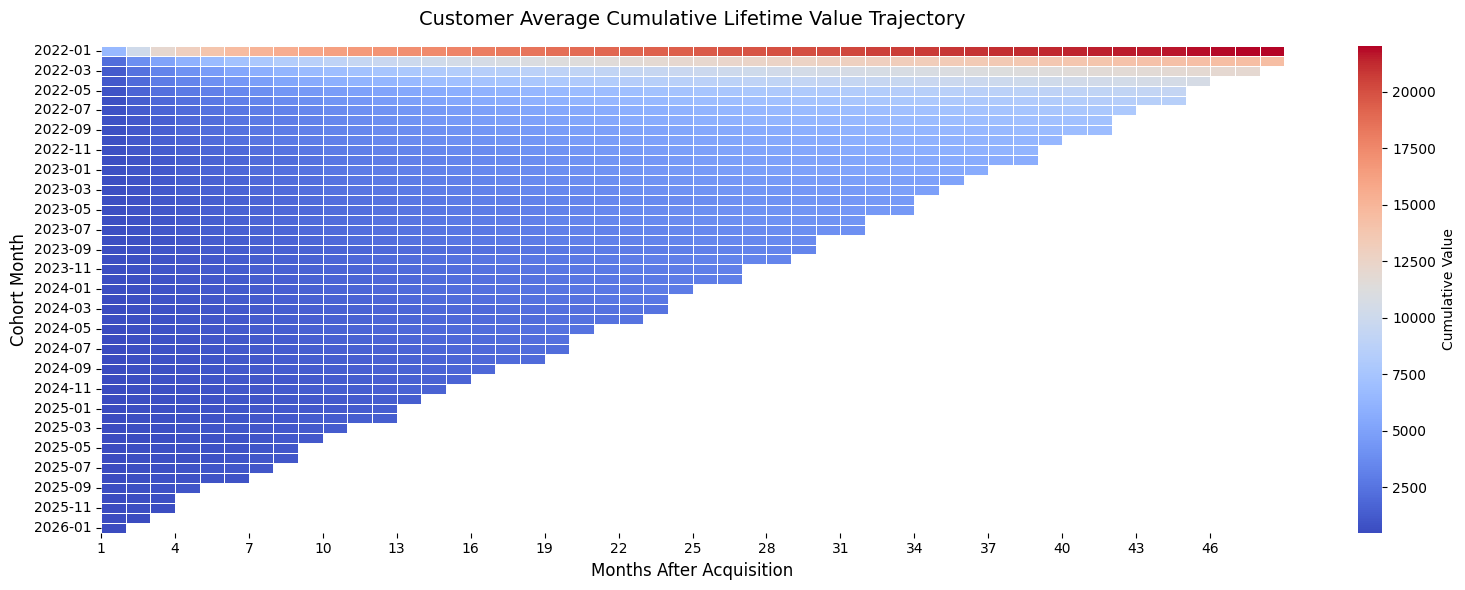

In [29]:
plt.figure(figsize=(16, 6))

ax = sns.heatmap(
    ltv_matrix,
    linewidths=0.5,
    cmap='coolwarm',
    vmin=ltv_matrix.min(axis=None),
    vmax=ltv_matrix.iloc[:, 1:].max(axis=None),
    cbar_kws={'label': 'Cumulative Value'}
)

plt.title("Customer Average Cumulative Lifetime Value Trajectory", fontsize=14, pad=15)
plt.ylabel("Cohort Month", fontsize=12)
plt.xlabel("Months After Acquisition", fontsize=12)

# Show every 3rd or 6th month on the x-axis to prevent crowding
ax.set_xticks(range(0, ltv_matrix.shape[1], 3))
ax.set_xticklabels(ltv_matrix.columns[::3], rotation=0)

plt.tight_layout()
plt.show()

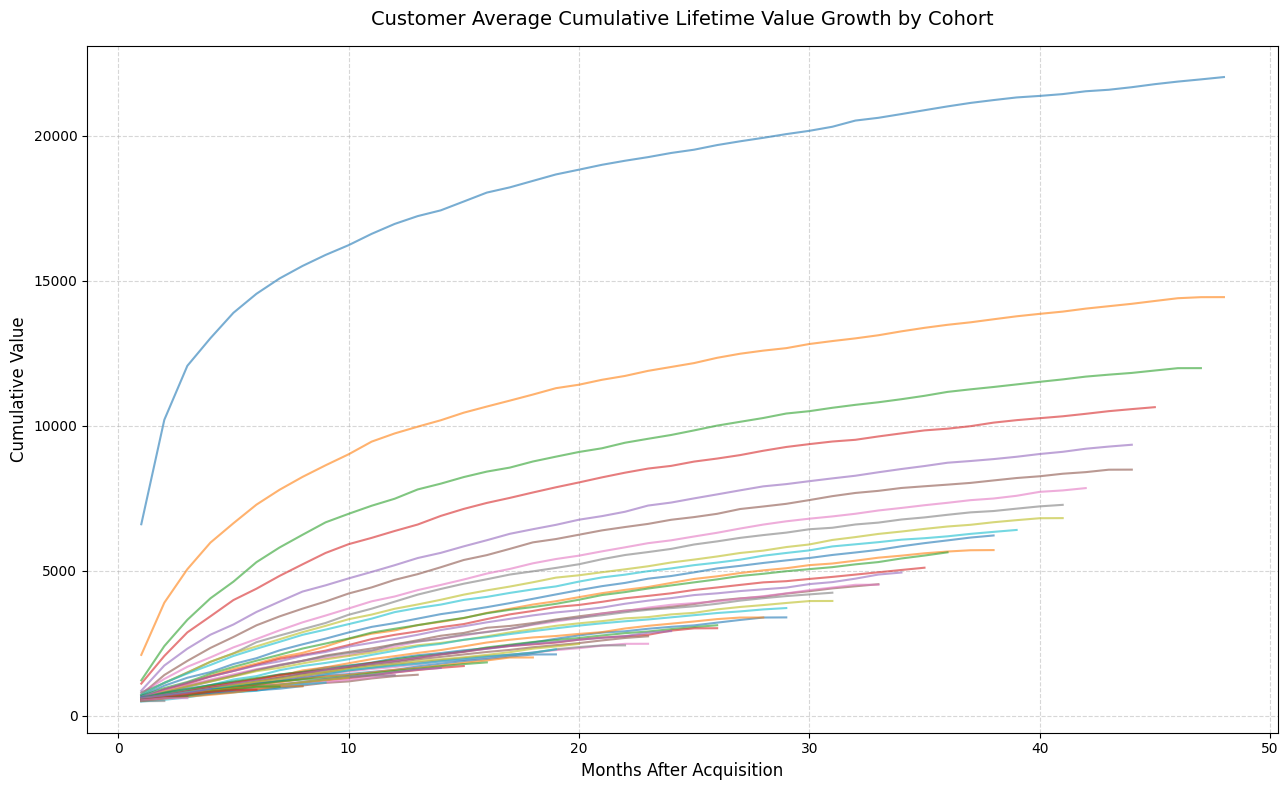

In [30]:
# line plot for easier analysis
plt.figure(figsize=(13, 8))

# each line represents a cohort month, x-axis is months after acquisition
ltv_matrix.T.plot(kind='line', ax=plt.gca(), legend=False, alpha=0.6)

plt.title("Customer Average Cumulative Lifetime Value Growth by Cohort", fontsize=14, pad=15)
plt.ylabel("Cumulative Value", fontsize=12)
plt.xlabel("Months After Acquisition", fontsize=12)

# add grid for easier reading
plt.grid(True, linestyle='--', alpha=0.5)
# plt.xlim(0,36)
# plt.ylim(0,5000)
plt.tight_layout()
plt.show()

* Average Cumulative Liftime Value for the first cohort month reach 22,000, indicating high revenue growth accumulated from 4 years worth of repeat spending.
* The Cumulative Lifetime Value continued to decline in the succeeding cohort months.
* Customers generate the vast majority of their lifetime value very early in their life cycle as indicated by rapid color transition from red to blue in the heatmap.
* Recent customers tend to have lower repeat purchases compared to the pioneer base.
